## Student Variables

In [1]:
import pandas as pd

In [2]:
# Students

path_stu_18 = r"C:\Users\ethan\Downloads\SAS_STU_QQQ\STU\cy07_msu_stu_qqq.sas7bdat"
path_stu_22 = r"C:\Users\ethan\Downloads\STU_QQQ_SAS\CY08MSP_STU_QQQ.SAS7BDAT"

# df_stu_2018 = pd.read_sas(path_stu_18, format="sas7bdat")
# df_stu_2022 = pd.read_sas(path_stu_22, format="sas7bdat")

In [3]:
import pyreadstat

# Read metadata only (very fast, almost no memory)
meta = pyreadstat.read_sas7bdat(
    path_stu_18,
    metadataonly=True
)[1]

all_cols = meta.column_names

# All plausible values
pv_vars = [
    col for col in all_cols
    if col.startswith("PV")
    and (
        "MATH" in col
        or "READ" in col
        or "SCIE" in col
    )
]

base_vars = [
    "CNT",
    "CNTSCHID",
    "CNTSTUID",
    "ESCS",
    # "PAREDINT",
    # "HISCED",
    # "MISCED",
    # "HOMEPOS",
    # "ST004D01T",
    # "AGE",
    # "ST001D01T",
    # "IMMIG",
    # "LANGN",
    # "REPEAT"
]

usecols = base_vars + pv_vars

df_18, meta = pyreadstat.read_sas7bdat(
    path_stu_18,
    usecols=usecols
)

asean = [
    "BRN", "KHM", "IDN", "LAO", "MYS",
    "MMR", "PHL", "SGP", "THA", "VNM"
]

df_stu_2018 = df_18[df_18["CNT"].isin(asean)]

In [4]:
import pyreadstat

# Read metadata only (very fast, almost no memory)
meta = pyreadstat.read_sas7bdat(
    path_stu_22,
    metadataonly=True
)[1]

all_cols = meta.column_names

# All plausible values
pv_vars = [
    col for col in all_cols
    if col.startswith("PV")
    and (
        "MATH" in col
        or "READ" in col
        or "SCIE" in col
    )
]

base_vars = [
    "CNT",
    "CNTSCHID",
    "CNTSTUID",
    "ESCS",
    # "PAREDINT",
    # "HISCED",
    # "MISCED",
    # "HOMEPOS",
    # "ST004D01T",
    # "AGE",
    # "ST001D01T",
    # "IMMIG",
    # "LANGN",
    # "REPEAT"
]

usecols = base_vars + pv_vars

df_22, meta = pyreadstat.read_sas7bdat(
    path_stu_22,
    usecols=usecols
)

asean = [
    "BRN", "KHM", "IDN", "LAO", "MYS",
    "MMR", "PHL", "SGP", "THA", "VNM"
]

df_stu_2022 = df_22[df_22["CNT"].isin(asean)]

In [5]:
# Find intersecting columns
common_cols = df_stu_2018.columns.intersection(df_stu_2022.columns)

# Filter both dataframes to only those columns
df_stu_2018_common = df_stu_2018[common_cols]
df_stu_2022_common = df_stu_2022[common_cols]

In [6]:
print(len(common_cols), "common columns")
print(common_cols.tolist())

34 common columns
['CNT', 'CNTSCHID', 'CNTSTUID', 'ESCS', 'PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH', 'PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ', 'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ', 'PV1SCIE', 'PV2SCIE', 'PV3SCIE', 'PV4SCIE', 'PV5SCIE', 'PV6SCIE', 'PV7SCIE', 'PV8SCIE', 'PV9SCIE', 'PV10SCIE']


In [7]:
common_cols

Index(['CNT', 'CNTSCHID', 'CNTSTUID', 'ESCS', 'PV1MATH', 'PV2MATH', 'PV3MATH',
       'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH',
       'PV10MATH', 'PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ',
       'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ', 'PV1SCIE',
       'PV2SCIE', 'PV3SCIE', 'PV4SCIE', 'PV5SCIE', 'PV6SCIE', 'PV7SCIE',
       'PV8SCIE', 'PV9SCIE', 'PV10SCIE'],
      dtype='object')

In [8]:
id_vars = [
    "CNT",        # country
    "CNTSCHID",   # school ID
    "CNTSTUID"    # student ID
]

In [9]:
confounders = [
        "ESCS",        # socio-economic status
        "PAREDINT",    # parental education (years)
        "HISCED",      # highest parental education
        "MISCED",      # mother's education
        "HOMEPOS",     # home possessions
        "ST004D01T",   # gender
        "AGE",         # age
        "ST001D01T",   # grade
        "IMMIG",       # immigrant background
        "LANGN",       # language spoken at home
        "REPEAT"       # grade repetition
]



In [10]:
# # 2. Build function
# # -----------------------------

# def build_analysis_df(df, year):
#     # Keep only PVs for math, reading, science
#     pv_vars = [
#         col for col in df.columns
#         if col.startswith("PV") and (
#             "MATH" in col or "READ" in col or "SCIE" in col
#         )
#     ]
    
#     # Combine variables
#     vars_to_keep = id_vars + confounders + pv_vars
    
#     # Keep only existing columns (robust across waves)
#     vars_existing = [v for v in vars_to_keep if v in df.columns]
    
#     # Subset
#     df_filtered = df[vars_existing].copy()
    
#     # Add year column
#     df_filtered["year"] = year
    
#     return df_filtered

# # -----------------------------
# # 3. Apply to both datasets
# # -----------------------------

# df18_filtered = build_analysis_df(df_stu_2018, 2018)
# df22_filtered = build_analysis_df(df_stu_2022, 2022)

# # -----------------------------
# # 4. Align columns
# # -----------------------------

# all_cols = sorted(set(df18_filtered.columns).union(df22_filtered.columns))

# df18_filtered = df18_filtered.reindex(columns=all_cols)
# df22_filtered = df22_filtered.reindex(columns=all_cols)

# # -----------------------------
# # 5. Combine
# # -----------------------------

# df_all = pd.concat([df18_filtered, df22_filtered], ignore_index=True)

# # -----------------------------
# # 6. Checks
# # -----------------------------

# pv_cols = [c for c in df_all.columns if c.startswith("PV")]

# print("Shape:", df_all.shape)
# print("Years:", df_all["year"].unique())
# print("PV columns:", len(pv_cols))
# print("Example PVs:", pv_cols[:10])

In [11]:
# -----------------------------
# 2. Build function
# -----------------------------

def build_analysis_df(df, year):
    # Keep only PVs for math, reading, science
    pv_vars = [
        col for col in df.columns
        if col.startswith("PV")
        and (
            "MATH" in col
            or "READ" in col
            or "SCIE" in col
        )
    ]

    # Combine variables
    vars_to_keep = id_vars + confounders + pv_vars

    # Keep only existing columns
    vars_existing = [v for v in vars_to_keep if v in df.columns]

    # Subset
    df_filtered = df[vars_existing].copy()

    # Add year
    df_filtered["year"] = year

    return df_filtered


# -----------------------------
# 3. Apply to both datasets
# -----------------------------

df18_filtered = build_analysis_df(df_stu_2018, 2018)
df22_filtered = build_analysis_df(df_stu_2022, 2022)


# -----------------------------
# 4. Combine directly
# -----------------------------

df_all = pd.concat(
    [df18_filtered, df22_filtered],
    ignore_index=True,
    sort=False
)


# -----------------------------
# 5. Optional: cleaner column ordering
# -----------------------------

pv_cols = [
    c for c in df_all.columns
    if c.startswith("PV")
]

non_pv_cols = [
    c for c in df_all.columns
    if c not in pv_cols
]

df_all = df_all[non_pv_cols + sorted(pv_cols)]


# -----------------------------
# 6. Checks
# -----------------------------

print("Shape:", df_all.shape)
print("Years:", sorted(df_all["year"].dropna().unique()))
print("Countries:", sorted(df_all["CNT"].dropna().unique()))
print("PV columns:", len(pv_cols))
print("Example PVs:", sorted(pv_cols)[:10])

Shape: (112681, 35)
Years: [2018, 2022]
Countries: ['BRN', 'IDN', 'KHM', 'MYS', 'PHL', 'SGP', 'THA', 'VNM']
PV columns: 30
Example PVs: ['PV10MATH', 'PV10READ', 'PV10SCIE', 'PV1MATH', 'PV1READ', 'PV1SCIE', 'PV2MATH', 'PV2READ', 'PV2SCIE', 'PV3MATH']


In [12]:
df_all.columns.tolist()

['CNT',
 'CNTSCHID',
 'CNTSTUID',
 'ESCS',
 'year',
 'PV10MATH',
 'PV10READ',
 'PV10SCIE',
 'PV1MATH',
 'PV1READ',
 'PV1SCIE',
 'PV2MATH',
 'PV2READ',
 'PV2SCIE',
 'PV3MATH',
 'PV3READ',
 'PV3SCIE',
 'PV4MATH',
 'PV4READ',
 'PV4SCIE',
 'PV5MATH',
 'PV5READ',
 'PV5SCIE',
 'PV6MATH',
 'PV6READ',
 'PV6SCIE',
 'PV7MATH',
 'PV7READ',
 'PV7SCIE',
 'PV8MATH',
 'PV8READ',
 'PV8SCIE',
 'PV9MATH',
 'PV9READ',
 'PV9SCIE']

In [13]:
df_all

,CNT,CNTSCHID,CNTSTUID,ESCS,year,PV10MATH,PV10READ,PV10SCIE,PV1MATH,PV1READ,...,PV6SCIE,PV7MATH,PV7READ,PV7SCIE,PV8MATH,PV8READ,PV8SCIE,PV9MATH,PV9READ,PV9SCIE
0,BRN,9600004.0,9600001.0,-1.5098,2018,305.523,298.695,352.419,275.067,319.465,...,344.385,327.829,335.350,357.833,289.944,294.169,349.156,330.321,299.682,348.140
1,BRN,9600039.0,9600002.0,1.3110,2018,503.689,450.521,458.745,555.674,475.030,...,465.234,457.191,436.752,442.654,450.496,433.401,485.909,478.227,407.575,451.189
2,BRN,9600013.0,9600003.0,-0.1704,2018,456.282,425.406,489.528,425.360,453.792,...,518.323,460.655,481.355,493.969,431.025,475.571,517.028,460.361,471.243,550.967
3,BRN,9600050.0,9600004.0,-0.4260,2018,315.271,320.959,285.057,345.277,327.125,...,344.550,376.146,341.981,394.856,385.809,405.192,408.605,412.617,361.492,382.302
4,BRN,9600027.0,9600005.0,-0.2566,2018,373.041,378.057,394.971,346.777,321.345,...,381.724,345.493,358.206,364.725,346.018,321.249,334.241,386.261,393.726,392.926
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112676,THA,76400011.0,76409133.0,-0.2684,2022,321.281,354.970,311.617,324.790,327.912,...,306.960,387.927,334.797,354.646,384.559,378.849,365.164,323.486,303.026,328.214
112677,THA,76400075.0,76409135.0,-0.3276,2022,542.980,493.195,556.611,528.037,512.949,...,591.011,531.740,469.462,561.807,560.207,546.447,592.770,579.549,519.212,578.720
112678,THA,76400167.0,76409136.0,-3.3113,2022,356.287,368.162,395.264,388.109,381.011,...,396.479,374.179,344.384,378.522,418.344,439.399,412.129,389.293,382.623,354.065
112679,THA,76400258.0,76409137.0,-1.8172,2022,379.072,343.715,377.490,401.596,368.361,...,372.515,365.045,307.399,371.393,303.000,297.984,418.982,380.288,359.099,426.134


## Teacher Variables

In [14]:
import pandas as pd 

# Teachers

path_tch_18 = r"C:\Users\ethan\Downloads\SAS_TCH_QQQ (1)\TCH\cy07_msu_tch_qqq.sas7bdat"
path_tch_22 = r"c:\Users\ethan\Downloads\TCH_QQQ_SAS\CY08MSP_TCH_QQQ.SAS7BDAT"

df_tch_2018 = pd.read_sas(path_tch_18, format="sas7bdat")
df_tch_2022 = pd.read_sas(path_tch_22, format="sas7bdat")

In [15]:
# Find intersecting columns
common_cols = df_tch_2018.columns.intersection(df_tch_2022.columns)

# Filter both dataframes to only those columns
df_tch_2018_common = df_tch_2018[common_cols]
df_tch_2022_common = df_tch_2022[common_cols]

In [16]:
print(len(common_cols), "common columns")
print(common_cols.tolist())

197 common columns
['CNTRYID', 'CNT', 'CNTSCHID', 'CNTTCHID', 'CYC', 'NatCen', 'STRATUM', 'SUBNATIO', 'OECD', 'TC001Q01NA', 'TC002Q01NA', 'TC007Q01NA', 'TC007Q02NA', 'TC014Q01HA', 'TC015Q01NA', 'TC018Q01NA', 'TC018Q01NB', 'TC018Q02NA', 'TC018Q02NB', 'TC018Q03NA', 'TC018Q03NB', 'TC018Q04NA', 'TC018Q04NB', 'TC018Q05NA', 'TC018Q05NB', 'TC018Q06NA', 'TC018Q06NB', 'TC018Q07NA', 'TC018Q07NB', 'TC018Q08NA', 'TC018Q08NB', 'TC018Q09NA', 'TC018Q09NB', 'TC018Q10NA', 'TC018Q10NB', 'TC018Q11NA', 'TC018Q11NB', 'TC045Q01NA', 'TC045Q01NB', 'TC045Q02NA', 'TC045Q02NB', 'TC045Q03NA', 'TC045Q03NB', 'TC045Q04NA', 'TC045Q04NB', 'TC045Q05NA', 'TC045Q05NB', 'TC045Q06NA', 'TC045Q06NB', 'TC045Q08NA', 'TC045Q08NB', 'TC045Q09NA', 'TC045Q09NB', 'TC045Q10NA', 'TC045Q10NB', 'TC045Q14NA', 'TC045Q14NB', 'TC045Q15NA', 'TC045Q15NB', 'TC045Q16HA', 'TC045Q16HB', 'TC045Q18HA', 'TC045Q18HB', 'TC021Q01NA', 'TC198Q01HA', 'TC198Q02HA', 'TC198Q04HA', 'TC198Q05HA', 'TC198Q06HA', 'TC198Q07HA', 'TC198Q08HA', 'TC198Q09HA', 'TC198Q1

In [17]:
id_vars = [
    "CNT",        # country
    "CNTSCHID",   # school ID
    "CNTTCHID"    # teacher ID
]

In [18]:
teacher_confounders = [
    "TC007Q02NA",  # experience
    "TC014Q01HA"  # qualification
    ]

In [19]:
# 2. Build function
# -----------------------------

def build_analysis_df(df, year):
    # Keep only PVs for math, reading, science
    pv_vars = [
        col for col in df.columns
        if col.startswith("PV") and (
            "MATH" in col or "READ" in col or "SCIE" in col
        )
    ]
    
    # Combine variables
    vars_to_keep = id_vars + teacher_confounders + pv_vars
    
    # Keep only existing columns (robust across waves)
    vars_existing = [v for v in vars_to_keep if v in df.columns]
    
    # Subset
    df_filtered = df[vars_existing].copy()
    
    # Add year column
    df_filtered["year"] = year
    
    return df_filtered

# -----------------------------
# 3. Apply to both datasets
# -----------------------------

df18_filtered = build_analysis_df(df_tch_2018, 2018)
df22_filtered = build_analysis_df(df_tch_2022, 2022)

# -----------------------------
# 4. Align columns
# -----------------------------

all_cols = sorted(set(df18_filtered.columns).union(df22_filtered.columns))

df18_filtered = df18_filtered.reindex(columns=all_cols)
df22_filtered = df22_filtered.reindex(columns=all_cols)

# -----------------------------
# 5. Combine
# -----------------------------

df_all_tch = pd.concat([df18_filtered, df22_filtered], ignore_index=True)

# -----------------------------
# 6. Checks
# -----------------------------

pv_cols = [c for c in df_all_tch.columns if c.startswith("PV")]

print("Shape:", df_all_tch.shape)
print("Years:", df_all_tch["year"].unique())
print("PV columns:", len(pv_cols))
print("Example PVs:", pv_cols[:10])

Shape: (175421, 6)
Years: [2018 2022]
PV columns: 0
Example PVs: []


In [20]:
df_all_tch.columns.tolist()

['CNT', 'CNTSCHID', 'CNTTCHID', 'TC007Q02NA', 'TC014Q01HA', 'year']

In [21]:
df_all_tch


,CNT,CNTSCHID,CNTTCHID,TC007Q02NA,TC014Q01HA,year
0,b'ALB',800057.0,800001.0,10.0,2.0,2018
1,b'ALB',800121.0,800002.0,5.0,1.0,2018
2,b'ALB',800140.0,800003.0,16.0,2.0,2018
3,b'ALB',800149.0,800004.0,3.0,2.0,2018
4,b'ALB',800095.0,800005.0,5.0,1.0,2018
...,...,...,...,...,...,...
175416,b'ARE',78400154.0,78411931.0,16.0,1.0,2022
175417,b'ARE',78400122.0,78411932.0,27.0,3.0,2022
175418,b'ARE',78400639.0,78411933.0,3.0,1.0,2022
175419,b'ARE',78400020.0,78411934.0,6.0,1.0,2022


In [22]:
summary_by_country = (
    df_all_tch
    .groupby("CNT")
    .agg(
        n_students=("CNT", "size"),
        avg_exp_available=("TC007Q02NA", lambda x: x.notna().mean()),
        avg_ed_available=("TC014Q01HA", lambda x: x.notna().mean())
    )
    .reset_index()
    .sort_values(["avg_exp_available", "avg_ed_available"], ascending=False)
)

summary_by_country

,CNT,n_students,avg_exp_available,avg_ed_available
2,b'AUS',11397,0.994648,0.985259
15,b'MAC',4739,0.985440,0.995358
13,b'KOR',7682,0.984900,0.986462
6,b'CRI',2476,0.983037,0.984249
17,b'MYS',8693,0.982975,0.988612
19,b'PER',8854,0.977863,0.980800
14,b'KSV',1290,0.965116,0.968217
11,b'GEO',3202,0.964085,0.971893
5,b'COL',2615,0.958700,0.959847
0,b'ALB',3375,0.941333,0.957630


# SCHool Variables

In [23]:
import pyreadstat
df_school_conf_2018, meta_2018 =  pyreadstat.read_sas7bdat(r"C:\Users\ethan\Downloads\SAS_SCH_QQQ\SCH\cy07_msu_sch_qqq.sas7bdat")
df_school_conf_2018["YEAR"] = 2018

df_school_conf_2022, meta_2022 =  pyreadstat.read_sas7bdat(r"C:\Users\ethan\Downloads\SCH_QQQ_SAS\CY08MSP_SCH_QQQ.SAS7BDAT")
df_school_conf_2022["YEAR"] = 2022


In [24]:
df_school_conf = pd.concat(
    [df_school_conf_2018, df_school_conf_2022],
    ignore_index=True
)

In [25]:
# df_school = pd.read_csv(r"C:\Users\ethan\Favorites\PISAxECAIR-Research\data\processed\df_merged_combined.csv")
df_school = pd.read_csv(r"C:\Users\ethan\Favorites\PISAxECAIR-Research\data\transformed\df_merged_combined_transformed_noinf.csv")

df_school

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,19.1751,2.7619,11.0625,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,8.5676,2.0167,4.9333,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,9.1188,2.4375,1.2625,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,9.2586,2.1200,3.8667,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,15.6078,4.5429,1.0000,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3087,THA,76400276.0,THA97,1.0,1.0,2.0,100.0,2022,0.0,2.0,...,19.6486,0.7000,3.7000,6.0,41.00,THA,377.752653,358.240835,411.188796,382.394095
3088,THA,76400277.0,THA97,1.0,1.0,3.0,85.0,2022,85.0,3.0,...,23.6757,1.6200,0.7400,4.0,69.00,THA,494.806138,474.063689,509.352244,492.740690
3089,THA,76400278.0,THA97,1.0,1.0,2.0,90.0,2022,30.0,1.0,...,20.0057,12.0000,1.7500,5.0,73.50,THA,462.219310,461.652469,487.667973,470.513251
3090,THA,76400279.0,THA97,1.0,1.0,1.0,100.0,2022,2.0,1.0,...,13.6111,0.8929,1.2857,4.0,56.00,THA,513.559200,432.402900,521.115300,489.025800


In [26]:
school_confounders = df_school_conf[
    [
        "CNTSCHID",      # or your actual school ID
        "YEAR",
        "SC001Q01TA",
        "SCHSIZE",
        "SC048Q03NA"
    ]
]

In [27]:
df_school = df_school.merge(
    school_confounders,
    on=["CNTSCHID", "YEAR"],
    how="left"
)

In [28]:
df_school.columns.tolist()

['CNT_x',
 'CNTSCHID',
 'STRATUM',
 'SC013Q01TA',
 'SC037Q02TA',
 'SC061Q01TA',
 'SC025Q01NA',
 'YEAR',
 'EXT_FUND',
 'EDU_MAT',
 'EDU_INFRA',
 'DIGI_CAP',
 'STU_TCH',
 'STU_COMP',
 'TCH_COMP',
 'X_ACTIV',
 'PRNT_ENG',
 'CNT_y',
 'MATH_school_weighted',
 'READ_school_weighted',
 'SCIE_school_weighted',
 'ALL_DOMAINS_school_weighted',
 'SC001Q01TA',
 'SCHSIZE',
 'SC048Q03NA']

In [29]:
df_school

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted,SC001Q01TA,SCHSIZE,SC048Q03NA
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347,3.0,1697.0,4.0
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539,2.0,634.0,85.0
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881,3.0,921.0,14.0
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349,2.0,1074.0,40.0
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128,3.0,796.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3087,THA,76400276.0,THA97,1.0,1.0,2.0,100.0,2022,0.0,2.0,...,6.0,41.00,THA,377.752653,358.240835,411.188796,382.394095,3.0,727.0,NaN
3088,THA,76400277.0,THA97,1.0,1.0,3.0,85.0,2022,85.0,3.0,...,4.0,69.00,THA,494.806138,474.063689,509.352244,492.740690,3.0,1752.0,NaN
3089,THA,76400278.0,THA97,1.0,1.0,2.0,90.0,2022,30.0,1.0,...,5.0,73.50,THA,462.219310,461.652469,487.667973,470.513251,5.0,3501.0,NaN
3090,THA,76400279.0,THA97,1.0,1.0,1.0,100.0,2022,2.0,1.0,...,4.0,56.00,THA,513.559200,432.402900,521.115300,489.025800,1.0,245.0,NaN


# Merging

In [30]:

# df_merged = pd.merge(
#     df_all,
#     df_school,
#     on='CNTSCHID',
#     how='inner'
# )

# print(df_merged)

In [31]:
# # Make school year column consistent
# df_school = df_school.rename(columns={"YEAR": "year"})
# df_school = df_school.rename(columns={"CNT": "CNT_x"})
# # Student + school
# df_merged = pd.merge(
#     df_all,
#     df_school,
#     on=["CNTSCHID", "year"],
#     how="inner",
#     suffixes=("", "_sch")
# )

# # Aggregate teacher data to school-year level first
# teacher_vars = [
#     "TC007Q01NA",
#     "TC014Q01HA",
#     "TC015Q01NA",
#     "TC021Q01NA"
# ]

# teacher_vars = [v for v in teacher_vars if v in df_all_tch.columns]

# df_tch_school = (
#     df_all_tch
#     .groupby(["CNTSCHID", "year"], as_index=False)[teacher_vars]
#     .mean()
# )

# # Student + school + teacher
# df_merged_complete = pd.merge(
#     df_merged,
#     df_tch_school,
#     on=["CNTSCHID", "year"],
#     how="inner",
#     suffixes=("", "_tch")
# )

# print("Student-school shape:", df_merged.shape)
# print("Final shape:", df_merged_complete.shape)
# print(df_merged_complete.head())

#### Student-School Merge

In [32]:
# Make school year column consistent
df_school = df_school.rename(columns={"YEAR": "year"})
df_school = df_school.rename(columns={"CNT": "CNT_x"})
# Student + school
df_merged = pd.merge(
    df_all,
    df_school,
    on=["CNTSCHID", "year"],
    how="inner",
    suffixes=("", "_sch")
)


In [33]:
df_merged 

,CNT,CNTSCHID,CNTSTUID,ESCS,year,PV10MATH,PV10READ,PV10SCIE,PV1MATH,PV1READ,...,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted,SC001Q01TA,SCHSIZE,SC048Q03NA
0,BRN,9600004.0,9600001.0,-1.5098,2018,305.523,298.695,352.419,275.067,319.465,...,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349,2.0,1074.0,40.0
1,BRN,9600039.0,9600002.0,1.3110,2018,503.689,450.521,458.745,555.674,475.030,...,4.0,80.00,BRN,449.347079,433.233092,438.165721,440.248631,1.0,1557.0,1.0
2,BRN,9600013.0,9600003.0,-0.1704,2018,456.282,425.406,489.528,425.360,453.792,...,4.0,25.75,BRN,501.147131,478.563343,517.555315,499.088596,2.0,1047.0,3.0
3,BRN,9600050.0,9600004.0,-0.4260,2018,315.271,320.959,285.057,345.277,327.125,...,4.0,6.75,BRN,378.841053,358.139932,378.362731,371.781239,2.0,857.0,27.0
4,BRN,9600027.0,9600005.0,-0.2566,2018,373.041,378.057,394.971,346.777,321.345,...,3.0,17.75,BRN,395.449849,370.716459,399.513442,388.559917,4.0,941.0,25.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112676,THA,76400011.0,76409133.0,-0.2684,2022,321.281,354.970,311.617,324.790,327.912,...,2.0,87.50,THA,371.113032,375.595413,395.742532,380.816992,2.0,511.0,NaN
112677,THA,76400075.0,76409135.0,-0.3276,2022,542.980,493.195,556.611,528.037,512.949,...,6.0,53.00,THA,467.805762,465.381476,496.039922,476.409053,3.0,1718.0,NaN
112678,THA,76400167.0,76409136.0,-3.3113,2022,356.287,368.162,395.264,388.109,381.011,...,4.0,3.75,THA,366.517201,350.295280,376.496979,364.436487,1.0,270.0,NaN
112679,THA,76400258.0,76409137.0,-1.8172,2022,379.072,343.715,377.490,401.596,368.361,...,2.0,55.00,THA,384.476566,360.630759,401.451349,382.186224,4.0,1969.0,NaN


#### Merged w/ teachers

In [34]:
# 1. Recode teacher education
df_all_tch["teacher_ed"] = df_all_tch["TC014Q01HA"].map({
    1: 1,   # teacher education <= 1 year
    2: 2,   # teacher education > 1 year
    3: 0    # no teacher education
})

In [35]:
# 2. Aggregate teacher variables to school-year level
tch_school = (
    df_all_tch
    .groupby(["CNTSCHID", "year"], as_index=False)
    .agg({
        "TC007Q02NA": "mean",   # total years teaching
        "teacher_ed": "mean"    # average teacher education score
    })
    .rename(columns={
        "TC007Q02NA": "avg_teacher_experience",
        "teacher_ed": "avg_teacher_education"
    })
)

In [36]:
# 3. Check that teacher data is now unique by school-year
tch_school.groupby(["CNTSCHID", "year"]).size().value_counts()

1    10385
Name: count, dtype: int64

In [37]:
# 4. Merge teacher school-level data onto your current dataframe
df_final = df_merged.merge(
    tch_school,
    on=["CNTSCHID", "year"],
    how="left"
)

In [38]:
# 5. Verify row count did not increase
print("Before merge:", df_merged.shape)
print("After merge :", df_final.shape)

Before merge: (112681, 58)
After merge : (112681, 60)


In [39]:
df_final

,CNT,CNTSCHID,CNTSTUID,ESCS,year,PV10MATH,PV10READ,PV10SCIE,PV1MATH,PV1READ,...,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted,SC001Q01TA,SCHSIZE,SC048Q03NA,avg_teacher_experience,avg_teacher_education
0,BRN,9600004.0,9600001.0,-1.5098,2018,305.523,298.695,352.419,275.067,319.465,...,BRN,379.067386,347.880933,372.468728,366.472349,2.0,1074.0,40.0,NaN,NaN
1,BRN,9600039.0,9600002.0,1.3110,2018,503.689,450.521,458.745,555.674,475.030,...,BRN,449.347079,433.233092,438.165721,440.248631,1.0,1557.0,1.0,NaN,NaN
2,BRN,9600013.0,9600003.0,-0.1704,2018,456.282,425.406,489.528,425.360,453.792,...,BRN,501.147131,478.563343,517.555315,499.088596,2.0,1047.0,3.0,NaN,NaN
3,BRN,9600050.0,9600004.0,-0.4260,2018,315.271,320.959,285.057,345.277,327.125,...,BRN,378.841053,358.139932,378.362731,371.781239,2.0,857.0,27.0,NaN,NaN
4,BRN,9600027.0,9600005.0,-0.2566,2018,373.041,378.057,394.971,346.777,321.345,...,BRN,395.449849,370.716459,399.513442,388.559917,4.0,941.0,25.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112676,THA,76400011.0,76409133.0,-0.2684,2022,321.281,354.970,311.617,324.790,327.912,...,THA,371.113032,375.595413,395.742532,380.816992,2.0,511.0,NaN,NaN,NaN
112677,THA,76400075.0,76409135.0,-0.3276,2022,542.980,493.195,556.611,528.037,512.949,...,THA,467.805762,465.381476,496.039922,476.409053,3.0,1718.0,NaN,NaN,NaN
112678,THA,76400167.0,76409136.0,-3.3113,2022,356.287,368.162,395.264,388.109,381.011,...,THA,366.517201,350.295280,376.496979,364.436487,1.0,270.0,NaN,NaN,NaN
112679,THA,76400258.0,76409137.0,-1.8172,2022,379.072,343.715,377.490,401.596,368.361,...,THA,384.476566,360.630759,401.451349,382.186224,4.0,1969.0,NaN,NaN,NaN


In [40]:
df_merged.isna().agg(["sum", "mean"]).T.rename(columns={"sum": "n_missing", "mean": "pct_missing"})

,n_missing,pct_missing
CNT,0.0,0.000000
CNTSCHID,0.0,0.000000
CNTSTUID,0.0,0.000000
ESCS,706.0,0.006265
year,0.0,0.000000
PV10MATH,5377.0,0.047719
PV10READ,5377.0,0.047719
PV10SCIE,5377.0,0.047719
PV1MATH,5377.0,0.047719
PV1READ,5377.0,0.047719


In [41]:
stop

NameError: name 'stop' is not defined

In [ ]:
# df_final.to_csv('student_school_data.csv', index=False)

In [ ]:
# 6. Check missing teacher data after merge
df_final[["avg_teacher_experience", "avg_teacher_education"]].isna().mean()

avg_teacher_experience    0.883033
avg_teacher_education     0.883033
dtype: float64

In [ ]:
teacher_mean_vars = [
    "avg_teacher_experience",
    "avg_teacher_education"
]

country_teacher_coverage = (
    df_final
    .groupby("CNT")[teacher_mean_vars]
    .apply(lambda x: x.notna().mean())
    .reset_index()
)

country_teacher_coverage

,CNT,avg_teacher_experience,avg_teacher_education
0,BRN,0.0,0.0
1,IDN,0.0,0.0
2,KHM,0.0,0.0
3,MYS,1.0,1.0
4,PHL,0.0,0.0
5,SGP,0.0,0.0
6,THA,0.0,0.0
7,VNM,0.0,0.0


In [ ]:
# Research-based candidate confounders for PISA-style student-school analyses
# Assumes your merged file is student-level and includes school variables joined by CNTSCHID.

possible_confounders = {
    "student_core": [
        "ESCS",        # socio-economic status
        "PAREDINT",    # parental education (years)
        "HISCED",      # highest parental education
        "MISCED",      # mother's education
        "HOMEPOS",     # home possessions
        "ST004D01T",   # gender
        "AGE",         # age
        "ST001D01T",   # grade
        "IMMIG",       # immigrant background
        "LANGN",       # language spoken at home
        "REPEAT"       # grade repetition
    ],

    "school_core": [
        "SC013Q01TA",  # public/private school
        "SC001Q01TA",  # school location / community size
        "SCHSIZE",     # school size
        "CLSIZE",      # class size (test language)
        "MCLSIZE",     # math class size
        "STRATIO",     # student-teacher ratio
        "SMRATIO",     # student-math-teacher ratio
        "PROATCE",     # proportion of teachers fully certified
        "STAFFSHORT",  # shortage of educational staff
        "EDUSHORT",    # shortage of educational material
        "SC211Q03JA",  # % disadvantaged students
        "SC211Q04JA",  # % immigrant students
        "SC211Q01JA",  # % students with different home/test language
        "SCHSEL"       # school selectivity
    ],

    # Useful if available/appropriate, but can be post-treatment depending on your design
    "use_with_caution": [
        "NEGSCLIM",    # negative school climate
        "STUBEHA",     # student-related factors affecting school climate
        "TEACHBEHA",   # teacher-related factors affecting school climate
        "OPENCUL",     # school openness culture/climate
        "ABGMATH"      # ability grouping in mathematics
    ],

    "teacher_core": [
        "TC007Q01NA",  # experience
        "TC014Q01HA",  # qualification
        "TC015Q01NA",  # certification
    ]
}

In [ ]:
confounders = {
    # ======================
    # STUDENT / FAMILY LEVEL
    # ======================
    "student_family": [
        "ESCS",        # socioeconomic status (core)
        "WEALTH",
        "HEDRES",
        "HOMEPOS",
        "HISCED",
        "HISEI",
        "IMMIG",
        "FAMSTRUC",
        "ST004D01T",   # gender
        "AGE",
        "ST001D01T",   # grade
        "REPEAT",      # grade repetition
        "LANGN"        # language at home
    ],

    # ======================
    # SCHOOL LEVEL
    # ======================
    "school": [
        "CLSIZE",
        "STRATIO",
        "SMRATIO",
        "SCMATEDU",
        "SCHLTYPE",
        "RATCMP15",
        "SCHSIZE",
        "SC001Q01TA"   # location (urban/rural)
    ],

}

# [SCRATCH/UNUSED] Causal Inference DoubleML (Presence of school play/musical)

In [ ]:
import pandas as pd
df_sch_2018 = pd.read_sas(r"C:\Users\ethan\Downloads\SAS_SCH_QQQ\SCH\cy07_msu_sch_qqq.sas7bdat", format="sas7bdat")
df_sch_2022 = pd.read_sas(r"C:\Users\ethan\Downloads\SCH_QQQ_SAS (1)\CY08MSP_SCH_QQQ.SAS7BDAT", format="sas7bdat")


## Confounders and Treatment

In [ ]:
# Research-based candidate confounders for PISA-style student-school analyses
# Assumes your merged file is student-level and includes school variables joined by CNTSCHID.
ID_COLS = ["CNTRYID", "CNTSTUID", "CNTSCHID", "CNT"]

possible_confounders = {
    "student_core": [
        "ESCS",        # socio-economic status
        # "PAREDINT",    # parental education (years)
        # "HISCED",      # highest parental education
        # "MISCED",      # mother's education
        # "HOMEPOS",     # home possessions
        "ST004D01T",   # gender
        "AGE",         # age
        "ST001D01T",   # grade
        "IMMIG",       # immigrant background
        "LANGN",       # language spoken at home
        "REPEAT"       # grade repetition
    ],

    "school_core": [
        "SC053Q02TA",  # TREATMENT VARIABLE: Presence of school play/music
        "SC013Q01TA",  # public/private school
        "SC001Q01TA",  # school location / community size
        "SCHSIZE",     # school size
        "CLSIZE",      # class size (test language)
        "MCLSIZE",     # math class size
        "STRATIO",     # student-teacher ratio
        "SMRATIO",     # student-math-teacher ratio
        "PROATCE",     # proportion of teachers fully certified
        "STAFFSHORT",  # shortage of educational staff
        "EDUSHORT",    # shortage of educational material
        "SC211Q03JA",  # % disadvantaged students
        "SC211Q04JA",  # % immigrant students
        "SC211Q01JA",  # % students with different home/test language
        "SCHSEL",       # school selectivity
        "LANGTEST"     # language of test administration
    ],

}

In [ ]:
school_cols = possible_confounders["school_core"]
cols_to_keep = ID_COLS + school_cols
existing_cols = [col for col in cols_to_keep if col in df_sch_2018.columns]

df_schoolconf_18 = df_sch_2018[existing_cols]

In [ ]:
school_cols = possible_confounders["school_core"]
cols_to_keep = ID_COLS + school_cols
existing_cols = [col for col in cols_to_keep if col in df_sch_2022.columns]

df_schoolconf_22 = df_sch_2022[existing_cols]

In [ ]:
school_cols = possible_confounders["school_core"]
cols_to_keep = ID_COLS + school_cols

# 2018
existing_cols_18 = [col for col in cols_to_keep if col in df_sch_2018.columns]
df_schoolconf_18 = df_sch_2018[existing_cols_18].copy()
df_schoolconf_18["YEAR"] = 2018

# 2022
existing_cols_22 = [col for col in cols_to_keep if col in df_sch_2022.columns]
df_schoolconf_22 = df_sch_2022[existing_cols_22].copy()
df_schoolconf_22["YEAR"] = 2022

In [ ]:
df_schoolconf_18

,CNTRYID,CNTSCHID,CNT,SC053Q02TA,SC013Q01TA,SC001Q01TA,SCHSIZE,CLSIZE,STRATIO,PROATCE,STAFFSHORT,EDUSHORT,LANGTEST,YEAR
0,8.0,800002.0,b'ALB',2.0,1.0,1.0,NaN,18.0,NaN,0.0000,-1.4551,1.2478,140.0,2018
1,8.0,800003.0,b'ALB',2.0,1.0,1.0,NaN,13.0,NaN,1.0000,-1.4551,0.6221,140.0,2018
2,8.0,800004.0,b'ALB',1.0,1.0,1.0,205.0,18.0,9.7619,1.0000,-1.4551,0.4591,140.0,2018
3,8.0,800005.0,b'ALB',1.0,1.0,2.0,NaN,23.0,NaN,0.6087,1.2432,1.3065,140.0,2018
4,8.0,800006.0,b'ALB',1.0,1.0,2.0,315.0,38.0,18.0000,1.0000,-1.4551,-0.2376,140.0,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21898,983.0,98300802.0,b'QRT',2.0,1.0,2.0,146.0,18.0,6.3478,1.0000,0.1964,1.0245,495.0,2018
21899,983.0,98300803.0,b'QRT',2.0,1.0,1.0,11.0,13.0,1.6923,0.0000,0.6736,0.6606,495.0,2018
21900,983.0,98300804.0,b'QRT',2.0,1.0,1.0,74.0,13.0,5.1034,1.0000,-1.4551,-0.2376,495.0,2018
21901,983.0,98300805.0,b'QRT',2.0,1.0,1.0,55.0,13.0,4.5833,1.0000,-0.0019,0.1111,495.0,2018


In [ ]:
df_schoolconf_22

,CNTRYID,CNTSCHID,CNT,SC053Q02TA,SC013Q01TA,SC001Q01TA,SCHSIZE,CLSIZE,MCLSIZE,STRATIO,SMRATIO,PROATCE,STAFFSHORT,EDUSHORT,SC211Q03JA,SC211Q04JA,SC211Q01JA,SCHSEL,YEAR
0,8.0,800001.0,b'ALB',2.0,1.0,3.0,652.0,33.0,33.0,16.9351,100.0,1.0000,-0.2968,1.2048,14.0,NaN,NaN,3.0,2022
1,8.0,800002.0,b'ALB',2.0,1.0,1.0,183.0,13.0,13.0,11.4375,61.0,1.0000,-1.4551,2.9595,NaN,NaN,NaN,3.0,2022
2,8.0,800003.0,b'ALB',1.0,2.0,2.0,121.0,13.0,13.0,7.1176,60.5,1.0000,0.2833,0.6299,1.0,NaN,77.0,3.0,2022
3,8.0,800004.0,b'ALB',2.0,1.0,3.0,1074.0,28.0,28.0,16.9134,100.0,0.9449,-1.4551,1.6863,16.0,NaN,11.0,3.0,2022
4,8.0,800005.0,b'ALB',2.0,1.0,3.0,317.0,18.0,18.0,11.7407,100.0,0.9630,-0.2129,1.2478,1.0,1.0,NaN,3.0,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21624,901.0,90100178.0,b'QUR',2.0,1.0,1.0,160.0,13.0,13.0,7.6190,80.0,1.0000,0.2633,0.4698,0.0,0.0,0.0,1.0,2022
21625,901.0,90100179.0,b'QUR',2.0,1.0,1.0,81.0,13.0,13.0,3.7674,32.4,0.0000,-0.1798,2.1904,0.0,0.0,0.0,1.0,2022
21626,901.0,90100180.0,b'QUR',1.0,1.0,2.0,896.0,28.0,28.0,12.9855,100.0,1.0000,0.0280,0.8339,8.0,0.0,0.0,2.0,2022
21627,901.0,90100181.0,b'QUR',2.0,1.0,4.0,733.0,18.0,33.0,14.9592,100.0,1.0000,0.2633,0.3066,0.0,0.0,0.0,3.0,2022


In [ ]:
student_cols = possible_confounders["student_core"]
cols_to_keep = ID_COLS + student_cols
existing_cols = [col for col in cols_to_keep if col in df_stu_2018.columns]

df_studentconf_18 = df_stu_2018[existing_cols]

In [ ]:
student_cols = possible_confounders["student_core"]
cols_to_keep = ID_COLS + student_cols
existing_cols = [col for col in cols_to_keep if col in df_stu_2022.columns]

df_studentconf_22 = df_stu_2022[existing_cols]

In [ ]:
df_studentconf_18

,CNTSTUID,CNTSCHID,CNT,ESCS,ST004D01T,AGE,ST001D01T,IMMIG,LANGN,REPEAT
71882,9600001.0,9600004.0,BRN,-1.5098,1.0,15.67,10.0,1.0,204.0,0.0
71883,9600002.0,9600039.0,BRN,1.3110,1.0,15.75,10.0,1.0,204.0,0.0
71884,9600003.0,9600013.0,BRN,-0.1704,1.0,15.50,10.0,1.0,204.0,0.0
71885,9600004.0,9600050.0,BRN,-0.4260,1.0,15.67,10.0,1.0,204.0,0.0
71886,9600005.0,9600027.0,BRN,-0.2566,1.0,15.58,10.0,1.0,204.0,0.0
...,...,...,...,...,...,...,...,...,...,...
530456,76409115.0,76400106.0,THA,-2.9578,2.0,16.00,9.0,1.0,555.0,0.0
530457,76409116.0,76400135.0,THA,-0.3370,1.0,15.75,9.0,1.0,616.0,1.0
530458,76409117.0,76400203.0,THA,-2.8268,2.0,16.00,10.0,1.0,555.0,0.0
530459,76409118.0,76400249.0,THA,0.1527,2.0,16.17,11.0,1.0,555.0,0.0


In [ ]:
df_studentconf_22

,CNTSTUID,CNTSCHID,CNT,ESCS,ST004D01T,AGE,ST001D01T,IMMIG,LANGN,REPEAT
64632,9600001.0,9600021.0,BRN,-0.1936,2.0,16.17,10.0,1.0,204.0,0.0
64633,9600002.0,9600045.0,BRN,1.0945,1.0,15.42,10.0,3.0,895.0,0.0
64634,9600003.0,9600018.0,BRN,-0.1573,2.0,15.75,10.0,1.0,204.0,0.0
64635,9600004.0,9600006.0,BRN,-0.8912,2.0,16.08,10.0,1.0,204.0,0.0
64636,9600005.0,9600004.0,BRN,0.0245,2.0,16.00,10.0,1.0,204.0,0.0
...,...,...,...,...,...,...,...,...,...,...
539968,76409133.0,76400011.0,THA,-0.2684,1.0,15.42,9.0,1.0,616.0,0.0
539969,76409135.0,76400075.0,THA,-0.3276,2.0,15.25,9.0,1.0,555.0,0.0
539970,76409136.0,76400167.0,THA,-3.3113,2.0,15.25,9.0,1.0,616.0,0.0
539971,76409137.0,76400258.0,THA,-1.8172,2.0,15.67,10.0,1.0,555.0,0.0


In [ ]:
# 2018 (READING)
read_cols_18 = [col for col in df_stu_2018.columns if col.startswith("PV") and "READ" in col]
df_stu_2018["READ_MEAN"] = df_stu_2018[read_cols_18].mean(axis=1)

# 2022 (MATH)
math_cols_22 = [col for col in df_stu_2022.columns if col.startswith("PV") and "MATH" in col]
df_stu_2022["MATH_MEAN"] = df_stu_2022[math_cols_22].mean(axis=1)

C:\Users\ethan\AppData\Local\Temp\ipykernel_25892\272229283.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_stu_2018["READ_MEAN"] = df_stu_2018[read_cols_18].mean(axis=1)
C:\Users\ethan\AppData\Local\Temp\ipykernel_25892\272229283.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_stu_2022["MATH_MEAN"] = df_stu_2022[math_cols_22].mean(axis=1)


In [ ]:
# 2018
student_cols = possible_confounders["student_core"]
cols_to_keep = ID_COLS + student_cols + ["READ_MEAN"]

existing_cols_18 = [col for col in cols_to_keep if col in df_stu_2018.columns]
df_studentconf_18 = df_stu_2018[existing_cols_18].copy()
df_studentconf_18["YEAR"] = 2018


# 2022
student_cols = possible_confounders["student_core"]
cols_to_keep = ID_COLS + student_cols + ["MATH_MEAN"]

existing_cols_22 = [col for col in cols_to_keep if col in df_stu_2022.columns]
df_studentconf_22 = df_stu_2022[existing_cols_22].copy()
df_studentconf_22["YEAR"] = 2022

In [ ]:
df_studentconf_22

,CNTSTUID,CNTSCHID,CNT,ESCS,ST004D01T,AGE,ST001D01T,IMMIG,LANGN,REPEAT,MATH_MEAN,YEAR
64632,9600001.0,9600021.0,BRN,-0.1936,2.0,16.17,10.0,1.0,204.0,0.0,299.3880,2022
64633,9600002.0,9600045.0,BRN,1.0945,1.0,15.42,10.0,3.0,895.0,0.0,535.3083,2022
64634,9600003.0,9600018.0,BRN,-0.1573,2.0,15.75,10.0,1.0,204.0,0.0,376.3725,2022
64635,9600004.0,9600006.0,BRN,-0.8912,2.0,16.08,10.0,1.0,204.0,0.0,423.0775,2022
64636,9600005.0,9600004.0,BRN,0.0245,2.0,16.00,10.0,1.0,204.0,0.0,387.2098,2022
...,...,...,...,...,...,...,...,...,...,...,...,...
539968,76409133.0,76400011.0,THA,-0.2684,1.0,15.42,9.0,1.0,616.0,0.0,337.4305,2022
539969,76409135.0,76400075.0,THA,-0.3276,2.0,15.25,9.0,1.0,555.0,0.0,557.6078,2022
539970,76409136.0,76400167.0,THA,-3.3113,2.0,15.25,9.0,1.0,616.0,0.0,386.0328,2022
539971,76409137.0,76400258.0,THA,-1.8172,2.0,15.67,10.0,1.0,555.0,0.0,379.9936,2022


In [ ]:
# 2018
df_merged_18 = df_studentconf_18.merge(
    df_schoolconf_18,
    on=["CNT", "CNTSCHID",],
    how="left",
    suffixes=("_stu", "_sch")
)

# 2022
df_merged_22 = df_studentconf_22.merge(
    df_schoolconf_22,
    on=["CNT", "CNTSCHID"],
    how="left",
    suffixes=("_stu", "_sch")
)

In [ ]:
print(df_merged_22)

         CNTSTUID    CNTSCHID  CNT    ESCS  ST004D01T    AGE  ST001D01T  \
0       9600001.0   9600021.0  BRN -0.1936        2.0  16.17       10.0   
1       9600002.0   9600045.0  BRN  1.0945        1.0  15.42       10.0   
2       9600003.0   9600018.0  BRN -0.1573        2.0  15.75       10.0   
3       9600004.0   9600006.0  BRN -0.8912        2.0  16.08       10.0   
4       9600005.0   9600004.0  BRN  0.0245        2.0  16.00       10.0   
...           ...         ...  ...     ...        ...    ...        ...   
59720  76409133.0  76400011.0  THA -0.2684        1.0  15.42        9.0   
59721  76409135.0  76400075.0  THA -0.3276        2.0  15.25        9.0   
59722  76409136.0  76400167.0  THA -3.3113        2.0  15.25        9.0   
59723  76409137.0  76400258.0  THA -1.8172        2.0  15.67       10.0   
59724  76409138.0  76400067.0  THA  0.6903        2.0  15.92       10.0   

       IMMIG  LANGN  REPEAT  ...  STRATIO  SMRATIO  PROATCE  STAFFSHORT  \
0        1.0  204.0     

In [ ]:
print(df_merged_18)

         CNTSTUID    CNTSCHID  CNT    ESCS  ST004D01T    AGE  ST001D01T  \
0       9600001.0   9600004.0  BRN -1.5098        1.0  15.67       10.0   
1       9600002.0   9600039.0  BRN  1.3110        1.0  15.75       10.0   
2       9600003.0   9600013.0  BRN -0.1704        1.0  15.50       10.0   
3       9600004.0   9600050.0  BRN -0.4260        1.0  15.67       10.0   
4       9600005.0   9600027.0  BRN -0.2566        1.0  15.58       10.0   
...           ...         ...  ...     ...        ...    ...        ...   
52951  76409115.0  76400106.0  THA -2.9578        2.0  16.00        9.0   
52952  76409116.0  76400135.0  THA -0.3370        1.0  15.75        9.0   
52953  76409117.0  76400203.0  THA -2.8268        2.0  16.00       10.0   
52954  76409118.0  76400249.0  THA  0.1527        2.0  16.17       11.0   
52955  76409120.0  76400161.0  THA -0.6286        1.0  15.75       10.0   

       IMMIG  LANGN  REPEAT  ...  SC013Q01TA  SC001Q01TA  SCHSIZE  CLSIZE  \
0        1.0  204.0   

## SEA Filter

In [ ]:
df_merged_18.columns.tolist()

['CNTSTUID',
 'CNTSCHID',
 'CNT',
 'ESCS',
 'ST004D01T',
 'AGE',
 'ST001D01T',
 'IMMIG',
 'LANGN',
 'REPEAT',
 'READ_MEAN',
 'YEAR_stu',
 'CNTRYID',
 'SC053Q02TA',
 'SC013Q01TA',
 'SC001Q01TA',
 'SCHSIZE',
 'CLSIZE',
 'STRATIO',
 'PROATCE',
 'STAFFSHORT',
 'EDUSHORT',
 'LANGTEST',
 'YEAR_sch']

In [ ]:
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

sea_countries = {"SGP", "THA", "IDN", "MYS", "PHL", "VNM", "BRN", "KHM"}

id_cols = [
    "CNTRYID_stu",
    "CNTSTUID",
    "CNTSCHID",
    "CNT",
    "YEAR_stu",
    "CNTRYID_sch",
    "YEAR_sch"
]

treatment_col = "SC053Q02TA"

categorical_code_cols = [
    "ST004D01T",
    "ST001D01T",
    "IMMIG",
    "LANGN",
    "REPEAT",
    "SC013Q01TA",
    "SC001Q01TA",
    "LANGTEST"
]

def decode_cnt_only(series):
    return series.apply(
        lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
    )

def sea_rf_impute_optimized(
    df,
    outcome_col,
    treatment=treatment_col,
    ids=id_cols,
    categorical_cols=categorical_code_cols,
    random_state=42
):
    # only keep columns that matter
    needed_cols = [c for c in df.columns if c in set(ids + [treatment, outcome_col] + categorical_cols) or c not in []]
    df = df.copy()

    # decode only CNT, not every object column
    df["CNT"] = decode_cnt_only(df["CNT"])

    # SEA filter first
    df = df[df["CNT"].isin(sea_countries)].copy()
    print(f"{outcome_col}: rows after SEA filter = {len(df)}")

    # drop rows with missing treatment/outcome
    df = df.dropna(subset=[treatment, outcome_col]).copy()
    print(f"{outcome_col}: rows after dropping missing treatment/outcome = {len(df)}")

    if df.empty:
        raise ValueError(f"No rows left for {outcome_col} after filtering.")

    # columns eligible for imputation: everything except ids, treatment, outcome
    exclude = set(ids + [treatment, outcome_col])
    candidate_cols = [c for c in df.columns if c not in exclude]

    # numeric only
    numeric_cols = [c for c in candidate_cols if pd.api.types.is_numeric_dtype(df[c])]

    # only columns that actually have missingness
    impute_cols = [c for c in numeric_cols if df[c].isna().any()]
    print(f"{outcome_col}: numeric columns to impute = {len(impute_cols)}")

    # convert numeric columns to float32 to save memory
    for c in numeric_cols + [treatment, outcome_col]:
        if c in df.columns and pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype("float32")

    # nothing to impute
    if not impute_cols:
        return df

    # fit imputer only on columns with missingness
    # use lighter forest settings
    imputer = IterativeImputer(
        estimator=RandomForestRegressor(
            n_estimators=30,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        ),
        max_iter=5,
        initial_strategy="median",
        skip_complete=True,
        random_state=random_state
    )

    # impute only the missing columns, not the full dataframe
    imputed_array = imputer.fit_transform(df[impute_cols])
    df[impute_cols] = imputed_array.astype("float32")

    # round coded categorical columns back
    round_cols = [c for c in categorical_cols if c in df.columns]
    for c in round_cols:
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = np.round(df[c])

    return df

In [ ]:
df_merged_18_sea_imp = sea_rf_impute_optimized(df_merged_18, "READ_MEAN")


READ_MEAN: rows after SEA filter = 52956
READ_MEAN: rows after dropping missing treatment/outcome = 0


ValueError: No rows left for READ_MEAN after filtering.

In [ ]:
df_merged_22_sea_imp = sea_rf_impute_optimized(df_merged_22, "MATH_MEAN")

MATH_MEAN: rows after SEA filter = 59725
MATH_MEAN: rows after dropping missing treatment/outcome = 57304
MATH_MEAN: numeric columns to impute = 20


C:\Users\ethan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [ ]:
df_merged_18_sea_imp

,CNTRYID_stu,CNTSTUID,CNTSCHID,CNT,ESCS,PAREDINT,HISCED,MISCED,HOMEPOS,ST004D01T,...,SC013Q01TA,SC001Q01TA,SCHSIZE,CLSIZE,STRATIO,PROATCE,STAFFSHORT,EDUSHORT,LANGTEST,YEAR_sch
71882,96.0,9600001.0,9600004.0,BRN,-1.5098,12.0,4.0,4.0,-1.8332,1.0,...,1.0,2.0,1074.0,28.0,9.2586,1.0000,-0.5869,0.1000,313.0,2018
71883,96.0,9600002.0,9600039.0,BRN,1.3110,16.0,6.0,6.0,0.7854,1.0,...,1.0,1.0,1557.0,23.0,11.4485,0.7794,-0.5869,-1.4212,313.0,2018
71884,96.0,9600003.0,9600013.0,BRN,-0.1704,12.0,4.0,1.0,-0.0509,1.0,...,2.0,2.0,1047.0,23.0,14.1486,1.0000,-1.4551,-1.4212,313.0,2018
71885,96.0,9600004.0,9600050.0,BRN,-0.4260,12.0,4.0,4.0,-0.6307,1.0,...,1.0,2.0,857.0,23.0,8.0849,0.9245,0.2100,1.6863,313.0,2018
71886,96.0,9600005.0,9600027.0,BRN,-0.2566,16.0,6.0,6.0,-1.3923,1.0,...,1.0,4.0,941.0,23.0,7.5887,1.0000,1.0883,0.9772,313.0,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
530456,764.0,76409115.0,76400106.0,THA,-2.9578,6.0,1.0,1.0,-2.4110,2.0,...,1.0,1.0,219.0,18.0,13.6875,1.0000,3.0959,2.4611,555.0,2018
530457,764.0,76409116.0,76400135.0,THA,-0.3370,12.0,4.0,1.0,0.6606,1.0,...,1.0,3.0,688.0,28.0,14.3333,1.0000,-0.7828,-0.6344,555.0,2018
530458,764.0,76409117.0,76400203.0,THA,-2.8268,3.0,0.0,0.0,-1.2815,2.0,...,1.0,1.0,1405.0,43.0,22.3016,1.0000,0.2100,1.2048,555.0,2018
530459,764.0,76409118.0,76400249.0,THA,0.1527,16.0,6.0,6.0,-1.2076,2.0,...,1.0,2.0,792.0,28.0,16.5000,1.0000,0.0131,1.2478,555.0,2018


In [ ]:
# pip install doubleml scikit-learn

import numpy as np
import pandas as pd

from doubleml import DoubleMLData, DoubleMLIRM, DoubleMLPLR
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# --------------------------------------------------
# 1. Column setup
# --------------------------------------------------
ID_COLS = [
    "CNTRYID_stu",
    "CNTSTUID",
    "CNTSCHID",
    "CNT",
    "YEAR_stu",
    "CNTRYID_sch",
    "YEAR_sch"
]

TREATMENT_COL = "SC053Q02TA"
OUTCOME_2018 = "READ_MEAN"
OUTCOME_2022 = "MATH_MEAN"

# --------------------------------------------------
# 2. Helper: prepare dataframe for DML
# --------------------------------------------------
def prepare_dml_data(df, outcome_col, treatment_col=TREATMENT_COL, id_cols=ID_COLS):
    df = df.copy()

    # decode bytes only if needed
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].apply(
                lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
            )

    # keep only rows with observed treatment and outcome
    df = df.dropna(subset=[outcome_col, treatment_col]).copy()

    # X = all non-ID, non-outcome, non-treatment columns
    x_cols = [
        c for c in df.columns
        if c not in id_cols + [outcome_col, treatment_col]
    ]

    # keep only numeric X columns for sklearn RF models
    x_cols = [c for c in x_cols if pd.api.types.is_numeric_dtype(df[c])]

    # make sure y, d, x are numeric
    keep_cols = x_cols + [outcome_col, treatment_col]
    df = df[keep_cols].copy()

    for c in keep_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=[outcome_col, treatment_col]).copy()

    return df, x_cols

# --------------------------------------------------
# 3. Helper: detect treatment type
# --------------------------------------------------
def detect_treatment_type(series):
    vals = series.dropna().unique()
    n_unique = len(vals)

    if n_unique == 2:
        return "binary"
    elif n_unique > 2 and pd.api.types.is_numeric_dtype(series):
        return "continuous"
    else:
        return "other"

# --------------------------------------------------
# 4. Run DML
# --------------------------------------------------
def run_dml(df, outcome_col, treatment_col=TREATMENT_COL, id_cols=ID_COLS, random_state=42):
    df_model, x_cols = prepare_dml_data(df, outcome_col, treatment_col, id_cols)

    treat_type = detect_treatment_type(df_model[treatment_col])
    print(f"\nOutcome: {outcome_col}")
    print(f"Rows used: {len(df_model):,}")
    print(f"Number of controls: {len(x_cols)}")
    print(f"Treatment type: {treat_type}")
    print("Treatment values:", sorted(df_model[treatment_col].dropna().unique())[:10])

    # -----------------------------
    # Binary treatment -> IRM
    # -----------------------------
    if treat_type == "binary":
        unique_vals = sorted(df_model[treatment_col].dropna().unique())
        mapping = {unique_vals[0]: 0, unique_vals[1]: 1}
        df_model[treatment_col] = df_model[treatment_col].map(mapping)

        dml_data = DoubleMLData(
            df_model,
            y_col=outcome_col,
            d_cols=treatment_col,
            x_cols=x_cols
        )

        ml_g = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        ml_m = RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        dml_model = DoubleMLIRM(
            dml_data,
            ml_g=ml_g,
            ml_m=ml_m,
            n_folds=5
        )
        dml_model.fit()

        print("\nBinary treatment mapping:", mapping)
        print(dml_model.summary)

        return dml_model, df_model, x_cols, mapping

    # -----------------------------
    # Continuous / multi-valued numeric treatment -> PLR
    # -----------------------------
    elif treat_type == "continuous":
        dml_data = DoubleMLData(
            df_model,
            y_col=outcome_col,
            d_cols=treatment_col,
            x_cols=x_cols
        )

        ml_l = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        ml_m = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        dml_model = DoubleMLPLR(
            dml_data,
            ml_l=ml_l,
            ml_m=ml_m,
            n_folds=5
        )
        dml_model.fit()

        print(dml_model.summary)

        return dml_model, df_model, x_cols, None

    else:
        raise ValueError(
            f"{treatment_col} is not binary or continuous numeric in a usable way. "
            f"Check value counts and recode treatment first."
        )

# --------------------------------------------------
# 5. Run year-specific models
# --------------------------------------------------
dml_2018, df_model_2018, xcols_2018, map_2018 = run_dml(
    df_merged_18_sea_imp,
    outcome_col=OUTCOME_2018
)

dml_2022, df_model_2022, xcols_2022, map_2022 = run_dml(
    df_merged_22_sea_imp,
    outcome_col=OUTCOME_2022
)

# --------------------------------------------------
# 6. Extract results neatly
# --------------------------------------------------
results = pd.DataFrame({
    "year": [2018, 2022],
    "outcome": [OUTCOME_2018, OUTCOME_2022],
    "coef": [float(dml_2018.coef[0]), float(dml_2022.coef[0])],
    "se": [float(dml_2018.se[0]), float(dml_2022.se[0])],
    "t_stat": [float(dml_2018.t_stat[0]), float(dml_2022.t_stat[0])],
    "pval": [float(dml_2018.pval[0]), float(dml_2022.pval[0])]
})

print("\nDML results:")
print(results)

C:\Users\ethan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Outcome: READ_MEAN
Rows used: 45,084
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t          P>|t|      2.5 %    97.5 %
SC053Q02TA -18.515368  0.557662 -33.201753  1.015635e-241 -19.608367 -17.42237

Outcome: MATH_MEAN
Rows used: 57,304
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]


KeyboardInterrupt: 

In [ ]:
!{sys.executable} -m pip install --no-cache-dir --force-reinstall --no-deps scikit-learn==1.2.2

'{sys.executable}' is not recognized as an internal or external command,
operable program or batch file.


## Normalize school size

In [ ]:
import numpy as np
import pandas as pd

def add_treatment(df):
    df = df.copy()

    df["SC004Q06NA"] = pd.to_numeric(df["SC004Q06NA"], errors="coerce")
    df["SCHSIZE"] = pd.to_numeric(df["SCHSIZE"], errors="coerce")

    # avoid division issues
    df.loc[df["SCHSIZE"] <= 0, "SCHSIZE"] = np.nan

    # normalize
    df["proj_per_student"] = df["SC004Q06NA"] / df["SCHSIZE"]

    # scale for interpretation
    df["proj_per_100_students"] = df["proj_per_student"] * 100

    return df

In [ ]:
df_merged_18_sea_imp = add_treatment(df_merged_18_sea_imp)
df_merged_22_sea_imp = add_treatment(df_merged_22_sea_imp)

In [ ]:
def clean_sample(df):
    df = df.copy()

    # remove extreme ratios (top 1%)
    q99 = df["proj_per_100_students"].quantile(0.99)
    df = df[df["proj_per_100_students"] < q99]

    # remove tiny schools (unstable denominators)
    df = df[df["SCHSIZE"] > 100]

    return df

In [ ]:
df_merged_18_clean = clean_sample(df_merged_18_sea_imp)
df_merged_22_clean = clean_sample(df_merged_22_sea_imp)

In [ ]:
ID_COLS = [
    "CNTRYID_stu",
    "CNTSTUID",
    "CNTSCHID",
    "CNT",
    "YEAR_stu",
    "CNTRYID_sch",
    "YEAR_sch"
]

def prepare_dml_data(df, outcome_col, treatment_col):
    df = df.copy()

    # drop missing outcome/treatment
    df = df.dropna(subset=[outcome_col, treatment_col]).copy()

    # exclude IDs + outcome + treatment
    exclude = set(ID_COLS + [outcome_col, treatment_col])

    # ❗ VERY IMPORTANT: remove SCHSIZE (used in treatment)
    if treatment_col == "proj_per_100_students":
        exclude.add("SCHSIZE")

    x_cols = [c for c in df.columns if c not in exclude]

    # numeric only (memory safe)
    x_cols = [c for c in x_cols if pd.api.types.is_numeric_dtype(df[c])]

    df_model = df[x_cols + [outcome_col, treatment_col]].copy()

    return df_model, x_cols

In [ ]:
from doubleml import DoubleMLData, DoubleMLPLR
from sklearn.ensemble import RandomForestRegressor

def run_dml(df, outcome_col, treatment_col, random_state=42):
    df_model, x_cols = prepare_dml_data(df, outcome_col, treatment_col)

    print(f"\nOutcome: {outcome_col}")
    print(f"Treatment: {treatment_col}")
    print(f"Rows used: {len(df_model):,}")
    print(f"Controls: {len(x_cols)}")

    dml_data = DoubleMLData(
        df_model,
        y_col=outcome_col,
        d_cols=treatment_col,
        x_cols=x_cols
    )

    # lighter RF (stable + memory safe)
    ml_l = RandomForestRegressor(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=-1,
        random_state=random_state
    )

    ml_m = RandomForestRegressor(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=-1,
        random_state=random_state
    )

    dml_model = DoubleMLPLR(
        dml_data,
        ml_l=ml_l,
        ml_m=ml_m,
        n_folds=5
    )

    dml_model.fit()
    print(dml_model.summary)

    return dml_model

In [ ]:
# 2018 (reading)
dml_2018 = run_dml(
    df_merged_18_clean,
    outcome_col="READ_MEAN",
    treatment_col="proj_per_100_students"
)

# 2022 (math)
dml_2022 = run_dml(
    df_merged_22_clean,
    outcome_col="MATH_MEAN",
    treatment_col="proj_per_100_students"
)


Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 44,360
Controls: 26
                            coef   std err         t         P>|t|      2.5 %  \
proj_per_100_students -45.135885  6.950959 -6.493476  8.387817e-11 -58.759514   

                          97.5 %  
proj_per_100_students -31.512256  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 56,223
Controls: 26
                           coef   std err         t         P>|t|   2.5 %  \
proj_per_100_students -4.571653  0.876469 -5.215989  1.828391e-07 -6.2895   

                         97.5 %  
proj_per_100_students -2.853805  


In [ ]:
results = pd.DataFrame({
    "year": [2018, 2022],
    "outcome": ["READ_MEAN", "MATH_MEAN"],
    "coef": [float(dml_2018.coef[0]), float(dml_2022.coef[0])],
    "se": [float(dml_2018.se[0]), float(dml_2022.se[0])],
    "t_stat": [float(dml_2018.t_stat[0]), float(dml_2022.t_stat[0])],
    "pval": [float(dml_2018.pval[0]), float(dml_2022.pval[0])]
})

print(results)

   year    outcome       coef        se    t_stat          pval
0  2018  READ_MEAN -45.135885  6.950959 -6.493476  8.387817e-11
1  2022  MATH_MEAN  -4.571653  0.876469 -5.215989  1.828391e-07


## CATE

In [ ]:
# pip install scikit-learn==1.2.2

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB 119.1 kB/s eta 0:01:10
   ---------------------------------------- 0.0/8.3 MB 119.1 kB/s eta 0:01:10
   ---------------------------------------- 0.1/8.3 MB 193.2 kB/s eta 0:00:43
   ---------------------------------------- 0.1/8.3 MB 218.6 kB/s eta 0:00:38
   ---------------------------------------- 0.1/8.3 MB 228.2 kB/s eta 0:00:36
   ---------------------------------------- 0.1/8.3 MB 228.2 kB/s eta 0:00:36
   ---------------------------------------- 0.1/8.3 MB 218.4 kB/s eta 0:00:38
   ---------------------------------------- 0.1/8.3 MB 218.4 kB/s eta 0:00:38
    ---------------------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
doubleml 0.11.2 requires scikit-learn>=1.6.0, but you have scikit-learn 1.2.2 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\ethan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
# pip install doubleml econml scikit-learn

   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
    --------------------------------------- 0.0/2.3 MB 1.3 MB/s eta 0:00:02
   - -------------------------------------- 0.1/2.3 MB 871.5 kB/s eta 0:00:03
   - -------------------------------------- 0.1/2.3 MB 726.2 kB/s eta 0:00:03
   -- ------------------------------------- 0.1/2.3 MB 847.9 kB/s eta 0:00:03
   --- ------------------------------------ 0.2/2.3 MB 803.1 kB/s eta 0:00:03
   --- ------------------------------------ 0.2/2.3 MB 784.3 kB/s eta 0:00:03
   --- ------------------------------------ 0.2/2.3 MB 689.9 kB/s eta 0:00:03
   --- ------------------------------------ 0.2/2.3 MB 595.3 kB/s eta 0:00:04
   --- --------------------------

  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\ethan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np

def run_subgroup_dml(
    df,
    outcome_col,
    treatment_col,
    subgroup_col,
    min_rows=1000,
    random_state=42
):
    results = []

    for group_value, df_g in df.groupby(subgroup_col):
        n = len(df_g)

        if n < min_rows:
            print(f"Skipping {subgroup_col}={group_value}: only {n} rows")
            continue

        try:
            model = run_dml(
                df_g,
                outcome_col=outcome_col,
                treatment_col=treatment_col,
                random_state=random_state
            )

            results.append({
                "subgroup_var": subgroup_col,
                "group": group_value,
                "n": n,
                "coef": float(model.coef[0]),
                "se": float(model.se[0]),
                "t_stat": float(model.t_stat[0]),
                "pval": float(model.pval[0]),
            })

        except Exception as e:
            print(f"Failed for {subgroup_col}={group_value}: {e}")

    return pd.DataFrame(results)

In [ ]:
def add_escs_quartiles(df):
    df = df.copy()
    df["ESCS_q"] = pd.qcut(df["ESCS"], 4, labels=["Q1_low", "Q2", "Q3", "Q4_high"])
    return df

In [ ]:
df_merged_18_clean = add_escs_quartiles(df_merged_18_clean)
df_merged_22_clean = add_escs_quartiles(df_merged_22_clean)

In [ ]:
escs_2018 = run_subgroup_dml(
    df_merged_18_clean,
    outcome_col="READ_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="ESCS_q",
    min_rows=1000
)

escs_2022 = run_subgroup_dml(
    df_merged_22_clean,
    outcome_col="MATH_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="ESCS_q",
    min_rows=1000
)

print("2018 ESCS heterogeneity")
print(escs_2018)

print("\n2022 ESCS heterogeneity")
print(escs_2022)

C:\Users\ethan\AppData\Local\Temp\ipykernel_35468\2193380999.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, df_g in df.groupby(subgroup_col):



Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 11,090
Controls: 26
                           coef   std err         t     P>|t|      2.5 %  \
proj_per_100_students  0.032709  8.230791  0.003974  0.996829 -16.099345   

                          97.5 %  
proj_per_100_students  16.164763  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 11,090
Controls: 26
                            coef    std err         t    P>|t|      2.5 %  \
proj_per_100_students -43.443646  11.014266 -3.944307  0.00008 -65.031211   

                          97.5 %  
proj_per_100_students -21.856081  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 11,090
Controls: 26
                          coef    std err         t     P>|t|      2.5 %  \
proj_per_100_students -43.8095  13.201808 -3.318447  0.000905 -69.684568   

                          97.5 %  
proj_per_100_students -17.934431  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 11,090
Contro

C:\Users\ethan\AppData\Local\Temp\ipykernel_35468\2193380999.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, df_g in df.groupby(subgroup_col):


                           coef   std err         t     P>|t|    2.5 %  \
proj_per_100_students -2.193163  1.591293 -1.378227  0.168133 -5.31204   

                         97.5 %  
proj_per_100_students  0.925713  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 14,056
Controls: 26
                           coef   std err         t     P>|t|     2.5 %  \
proj_per_100_students -1.288149  1.648765 -0.781281  0.434637 -4.519668   

                         97.5 %  
proj_per_100_students  1.943371  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 14,055
Controls: 26
                           coef   std err        t     P>|t|     2.5 %  \
proj_per_100_students -2.865684  1.840835 -1.55673  0.119534 -6.473655   

                         97.5 %  
proj_per_100_students  0.742287  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 14,055
Controls: 26
                           coef   std err         t   P>|t|    2.5 %    97.5 %
proj_per_100_stu

In [ ]:
gender_2018 = run_subgroup_dml(
    df_merged_18_clean,
    outcome_col="READ_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="ST004D01T",
    min_rows=1000
)

gender_2022 = run_subgroup_dml(
    df_merged_22_clean,
    outcome_col="MATH_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="ST004D01T",
    min_rows=1000
)

print("2018 gender heterogeneity")
print(gender_2018)

print("\n2022 gender heterogeneity")
print(gender_2022)


Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 22,916
Controls: 26
                            coef   std err         t     P>|t|      2.5 %  \
proj_per_100_students -43.406964  9.602639 -4.520316  0.000006 -62.227791   

                          97.5 %  
proj_per_100_students -24.586138  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 21,444
Controls: 26
                            coef   std err         t     P>|t|      2.5 %  \
proj_per_100_students -44.467098  9.431645 -4.714671  0.000002 -62.952782   

                          97.5 %  
proj_per_100_students -25.981415  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 28,767
Controls: 26
                          coef   std err         t     P>|t|     2.5 %  \
proj_per_100_students -4.39619  1.116767 -3.936533  0.000083 -6.585013   

                         97.5 %  
proj_per_100_students -2.207367  

Outcome: MATH_MEAN
Treatment: proj_per_100_students
Rows used: 27,456
Controls: 

In [ ]:
country_2018 = run_subgroup_dml(
    df_merged_18_clean,
    outcome_col="READ_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="CNT",
    min_rows=1000
)

country_2022 = run_subgroup_dml(
    df_merged_22_clean,
    outcome_col="MATH_MEAN",
    treatment_col="proj_per_100_students",
    subgroup_col="CNT",
    min_rows=1000
)

print("2018 country heterogeneity")
print(country_2018.sort_values("coef"))

print("\n2022 country heterogeneity")
print(country_2022.sort_values("coef"))


Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 6,828
Controls: 26
                            coef   std err         t     P>|t|     2.5 %  \
proj_per_100_students  56.511343  44.13343  1.280466  0.200381 -29.98859   

                           97.5 %  
proj_per_100_students  143.011275  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 9,388
Controls: 26
                            coef    std err         t     P>|t|       2.5 %  \
proj_per_100_students -95.501724  24.475082 -3.901998  0.000095 -143.472004   

                          97.5 %  
proj_per_100_students -47.531445  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 6,111
Controls: 26
                            coef    std err         t    P>|t|      2.5 %  \
proj_per_100_students -10.973799  33.491571 -0.327659  0.74317 -76.616073   

                          97.5 %  
proj_per_100_students  54.668475  

Outcome: READ_MEAN
Treatment: proj_per_100_students
Rows used: 7,191
Co

In [ ]:
def label_results(df_res, year, outcome):
    df_res = df_res.copy()
    df_res["year"] = year
    df_res["outcome"] = outcome
    return df_res

all_heterogeneity = pd.concat([
    label_results(escs_2018, 2018, "READ_MEAN"),
    label_results(escs_2022, 2022, "MATH_MEAN"),
    label_results(gender_2018, 2018, "READ_MEAN"),
    label_results(gender_2022, 2022, "MATH_MEAN"),
    label_results(country_2018, 2018, "READ_MEAN"),
    label_results(country_2022, 2022, "MATH_MEAN"),
], ignore_index=True)

print(all_heterogeneity)

   subgroup_var    group      n        coef         se    t_stat      pval  \
0        ESCS_q   Q1_low  11090    0.032709   8.230791  0.003974  0.996829   
1        ESCS_q       Q2  11090  -43.443646  11.014266 -3.944307  0.000080   
2        ESCS_q       Q3  11090  -43.809500  13.201808 -3.318447  0.000905   
3        ESCS_q  Q4_high  11090  -32.020210  11.294342 -2.835067  0.004582   
4        ESCS_q   Q1_low  14057   -2.193163   1.591293 -1.378227  0.168133   
5        ESCS_q       Q2  14056   -1.288149   1.648765 -0.781281  0.434637   
6        ESCS_q       Q3  14055   -2.865684   1.840835 -1.556730  0.119534   
7        ESCS_q  Q4_high  14055   -5.204112   1.495093 -3.480795  0.000500   
8     ST004D01T      1.0  22916  -43.406964   9.602639 -4.520316  0.000006   
9     ST004D01T      2.0  21444  -44.467098   9.431645 -4.714671  0.000002   
10    ST004D01T      1.0  28767   -4.396190   1.116767 -3.936533  0.000083   
11    ST004D01T      2.0  27456   -3.829310   1.185968 -3.228849

## CATE school play

In [ ]:
# pip install doubleml scikit-learn

import numpy as np
import pandas as pd

from doubleml import DoubleMLData, DoubleMLIRM, DoubleMLPLR
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


# 1. Column setup

ID_COLS = [
    "CNTRYID_stu",
    "CNTSTUID",
    "CNTSCHID",
    "CNT",
    "YEAR_stu",
    "CNTRYID_sch",
    "YEAR_sch"
]

TREATMENT_COL = "SC053Q02TA"
OUTCOME_2018 = "READ_MEAN"
OUTCOME_2022 = "MATH_MEAN"


# 2. Helper: prepare dataframe for DML

def prepare_dml_data(df, outcome_col, treatment_col=TREATMENT_COL, id_cols=ID_COLS):
    df = df.copy()

    # decode bytes only if needed
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].apply(
                lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
            )

    # keep only rows with observed treatment and outcome
    df = df.dropna(subset=[outcome_col, treatment_col]).copy()

    # X = all non-ID, non-outcome, non-treatment columns
    x_cols = [
        c for c in df.columns
        if c not in id_cols + [outcome_col, treatment_col]
    ]

    # keep only numeric X columns for sklearn RF models
    x_cols = [c for c in x_cols if pd.api.types.is_numeric_dtype(df[c])]

    # make sure y, d, x are numeric
    keep_cols = x_cols + [outcome_col, treatment_col]
    df = df[keep_cols].copy()

    for c in keep_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=[outcome_col, treatment_col]).copy()

    return df, x_cols


# 3. Helper: detect treatment type

def detect_treatment_type(series):
    vals = series.dropna().unique()
    n_unique = len(vals)

    if n_unique == 2:
        return "binary"
    elif n_unique > 2 and pd.api.types.is_numeric_dtype(series):
        return "continuous"
    else:
        return "other"


# 4. Run DML

def run_dml(df, outcome_col, treatment_col=TREATMENT_COL, id_cols=ID_COLS, random_state=42):
    df_model, x_cols = prepare_dml_data(df, outcome_col, treatment_col, id_cols)

    treat_type = detect_treatment_type(df_model[treatment_col])
    print(f"\nOutcome: {outcome_col}")
    print(f"Rows used: {len(df_model):,}")
    print(f"Number of controls: {len(x_cols)}")
    print(f"Treatment type: {treat_type}")
    print("Treatment values:", sorted(df_model[treatment_col].dropna().unique())[:10])

    # -----------------------------
    # Binary treatment -> IRM
    # -----------------------------
    if treat_type == "binary":
        unique_vals = sorted(df_model[treatment_col].dropna().unique())
        mapping = {unique_vals[0]: 0, unique_vals[1]: 1}
        df_model[treatment_col] = df_model[treatment_col].map(mapping)

        dml_data = DoubleMLData(
            df_model,
            y_col=outcome_col,
            d_cols=treatment_col,
            x_cols=x_cols
        )

        ml_g = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        ml_m = RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        dml_model = DoubleMLIRM(
            dml_data,
            ml_g=ml_g,
            ml_m=ml_m,
            n_folds=5
        )
        dml_model.fit()

        print("\nBinary treatment mapping:", mapping)
        print(dml_model.summary)

        return dml_model, df_model, x_cols, mapping

  
    # Continuous / multi-valued numeric treatment -> PLR
 
    elif treat_type == "continuous":
        dml_data = DoubleMLData(
            df_model,
            y_col=outcome_col,
            d_cols=treatment_col,
            x_cols=x_cols
        )

        ml_l = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        ml_m = RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=random_state
        )

        dml_model = DoubleMLPLR(
            dml_data,
            ml_l=ml_l,
            ml_m=ml_m,
            n_folds=5
        )
        dml_model.fit()

        print(dml_model.summary)

        return dml_model, df_model, x_cols, None

    else:
        raise ValueError(
            f"{treatment_col} is not binary or continuous numeric in a usable way. "
            f"Check value counts and recode treatment first."
        )


# 5. Add subgroup variables

def add_subgroups(df):
    df = df.copy()

    # ESCS quartiles
    if "ESCS" in df.columns:
        escs_nonmissing = df["ESCS"].dropna()
        if len(escs_nonmissing) > 0:
            df["ESCS_q"] = pd.qcut(
                df["ESCS"],
                4,
                labels=["Q1_low", "Q2", "Q3", "Q4_high"],
                duplicates="drop"
            )

    return df

df_merged_18_sea_imp = add_subgroups(df_merged_18_sea_imp)
df_merged_22_sea_imp = add_subgroups(df_merged_22_sea_imp)


# 6. Subgroup DML runner

def run_subgroup_dml(
    df,
    outcome_col,
    treatment_col,
    subgroup_col,
    min_rows=1000,
    random_state=42
):
    results = []

    for group_value, df_g in df.groupby(subgroup_col, dropna=True):
        n = len(df_g)

        if n < min_rows:
            print(f"Skipping {subgroup_col}={group_value}: only {n} rows")
            continue

        try:
            model, _, _, mapping = run_dml(
                df_g,
                outcome_col=outcome_col,
                treatment_col=treatment_col,
                random_state=random_state
            )

            results.append({
                "subgroup_var": subgroup_col,
                "group": str(group_value),
                "n": n,
                "coef": float(model.coef[0]),
                "se": float(model.se[0]),
                "t_stat": float(model.t_stat[0]),
                "pval": float(model.pval[0]),
                "mapping": str(mapping) if mapping is not None else None
            })

        except Exception as e:
            print(f"Failed for {subgroup_col}={group_value}: {e}")

    return pd.DataFrame(results)


# 7. Main pooled models

dml_2018, df_model_2018, xcols_2018, map_2018 = run_dml(
    df_merged_18_sea_imp,
    outcome_col=OUTCOME_2018
)

dml_2022, df_model_2022, xcols_2022, map_2022 = run_dml(
    df_merged_22_sea_imp,
    outcome_col=OUTCOME_2022
)


# 8. Heterogeneity: ESCS quartiles

escs_2018 = run_subgroup_dml(
    df_merged_18_sea_imp,
    outcome_col=OUTCOME_2018,
    treatment_col=TREATMENT_COL,
    subgroup_col="ESCS_q",
    min_rows=1000
)

escs_2022 = run_subgroup_dml(
    df_merged_22_sea_imp,
    outcome_col=OUTCOME_2022,
    treatment_col=TREATMENT_COL,
    subgroup_col="ESCS_q",
    min_rows=1000
)


# 9. Heterogeneity: gender

gender_2018 = run_subgroup_dml(
    df_merged_18_sea_imp,
    outcome_col=OUTCOME_2018,
    treatment_col=TREATMENT_COL,
    subgroup_col="ST004D01T",
    min_rows=1000
)

gender_2022 = run_subgroup_dml(
    df_merged_22_sea_imp,
    outcome_col=OUTCOME_2022,
    treatment_col=TREATMENT_COL,
    subgroup_col="ST004D01T",
    min_rows=1000
)


# 10. Heterogeneity: country

country_2018 = run_subgroup_dml(
    df_merged_18_sea_imp,
    outcome_col=OUTCOME_2018,
    treatment_col=TREATMENT_COL,
    subgroup_col="CNT",
    min_rows=1000
)

country_2022 = run_subgroup_dml(
    df_merged_22_sea_imp,
    outcome_col=OUTCOME_2022,
    treatment_col=TREATMENT_COL,
    subgroup_col="CNT",
    min_rows=1000
)


# 11. Extract pooled results neatly

results = pd.DataFrame({
    "year": [2018, 2022],
    "outcome": [OUTCOME_2018, OUTCOME_2022],
    "coef": [float(dml_2018.coef[0]), float(dml_2022.coef[0])],
    "se": [float(dml_2018.se[0]), float(dml_2022.se[0])],
    "t_stat": [float(dml_2018.t_stat[0]), float(dml_2022.t_stat[0])],
    "pval": [float(dml_2018.pval[0]), float(dml_2022.pval[0])]
})

print("\nPooled DML results:")
print(results)


# 12. Combine subgroup results

def label_results(df_res, year, outcome):
    df_res = df_res.copy()
    df_res["year"] = year
    df_res["outcome"] = outcome
    return df_res

all_heterogeneity = pd.concat([
    label_results(escs_2018, 2018, OUTCOME_2018),
    label_results(escs_2022, 2022, OUTCOME_2022),
    label_results(gender_2018, 2018, OUTCOME_2018),
    label_results(gender_2022, 2022, OUTCOME_2022),
    label_results(country_2018, 2018, OUTCOME_2018),
    label_results(country_2022, 2022, OUTCOME_2022),
], ignore_index=True)

print("\nSubgroup heterogeneity results:")
print(all_heterogeneity)


Outcome: READ_MEAN
Rows used: 45,084
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t          P>|t|      2.5 %  \
SC053Q02TA -18.450653  0.557684 -33.084393  4.983476e-240 -19.543695   

               97.5 %  
SC053Q02TA -17.357612  

Outcome: MATH_MEAN
Rows used: 57,304
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err          t  P>|t|      2.5 %    97.5 %
SC053Q02TA -17.83251  0.431023 -41.372503    0.0 -18.677299 -16.98772

Outcome: READ_MEAN
Rows used: 11,271
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]


C:\Users\ethan\AppData\Local\Temp\ipykernel_33436\134898942.py:217: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, df_g in df.groupby(subgroup_col, dropna=True):



Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err         t         P>|t|     2.5 %    97.5 %
SC053Q02TA -6.144693  0.893178 -6.879586  6.002668e-12 -7.895289 -4.394097

Outcome: READ_MEAN
Rows used: 11,271
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err          t         P>|t|      2.5 %     97.5 %
SC053Q02TA -13.68192  1.066038 -12.834365  1.052626e-37 -15.771316 -11.592524

Outcome: READ_MEAN
Rows used: 11,271
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err          t         P>|t|      2.5 %     97.5 %
SC053Q02TA -20.01512  1.148055 -17.433943  4.559082e-68 -22.265265 -17.764974

Outcome: READ_MEAN
Rows used: 11,271
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   

C:\Users\ethan\AppData\Local\Temp\ipykernel_33436\134898942.py:217: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, df_g in df.groupby(subgroup_col, dropna=True):



Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t         P>|t|      2.5 %     97.5 %
SC053Q02TA -14.958543  0.706458 -21.174004  1.658517e-99 -16.343175 -13.573911

Outcome: MATH_MEAN
Rows used: 14,325
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t         P>|t|      2.5 %     97.5 %
SC053Q02TA -14.280823  0.825849 -17.292301  5.376274e-67 -15.899456 -12.662189

Outcome: MATH_MEAN
Rows used: 14,326
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t         P>|t|      2.5 %    97.5 %
SC053Q02TA -15.306841  0.935151 -16.368318  3.219886e-60 -17.139703 -13.47398

Outcome: MATH_MEAN
Rows used: 14,326
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
             

...


Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t         P>|t|      2.5 %    97.5 %
SC053Q02TA -11.262587  0.972189 -11.584776  4.922535e-31 -13.168042 -9.357132

Outcome: READ_MEAN
Rows used: 9,745
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t          P>|t|      2.5 %  \
SC053Q02TA -19.748186  0.838034 -23.564886  8.834757e-123 -21.390703   

               97.5 %  
SC053Q02TA -18.105668  

Outcome: READ_MEAN
Rows used: 6,081
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err         t         P>|t|      2.5 %    97.5 %
SC053Q02TA -10.041274  1.206009 -8.326033  8.359671e-17 -12.405009 -7.677539

Outcome: READ_MEAN
Rows used: 7,233
Number of controls: 20
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1

C:\Users\ethan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\doubleml\utils\propensity_score_processing.py:272: UserWarning: Propensity predictions  from learner ml_m are close to zero or one (eps=1e-12).
  warnings.warn(



Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t          P>|t|      2.5 %  \
SC053Q02TA -27.460833  0.991788 -27.688209  9.682448e-169 -29.404702   

               97.5 %  
SC053Q02TA -25.516964  

Outcome: MATH_MEAN
Rows used: 13,327
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err         t         P>|t|     2.5 %    97.5 %
SC053Q02TA -5.199873  0.585085 -8.887388  6.256242e-19 -6.346617 -4.053128

Outcome: MATH_MEAN
Rows used: 3,180
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]


C:\Users\ethan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\doubleml\utils\propensity_score_processing.py:272: UserWarning: Propensity predictions  from learner ml_m are close to zero or one (eps=1e-12).
  warnings.warn(



Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef  std err         t    P>|t|     2.5 %    97.5 %
SC053Q02TA -3.589909  1.09732 -3.271523  0.00107 -5.740617 -1.439201

Outcome: MATH_MEAN
Rows used: 7,069
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err          t         P>|t|      2.5 %    97.5 %
SC053Q02TA -9.629443  0.862203 -11.168415  5.821008e-29 -11.319331 -7.939556

Outcome: MATH_MEAN
Rows used: 7,193
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                coef   std err         t         P>|t|     2.5 %    97.5 %
SC053Q02TA -5.511122  0.640473 -8.604769  7.647068e-18 -6.766426 -4.255818

Outcome: MATH_MEAN
Rows used: 6,475
Number of controls: 25
Treatment type: binary
Treatment values: [1.0, 2.0]

Binary treatment mapping: {1.0: 0, 2.0: 1}
                 coef   std err          t    

## Presence of School play/musical results

# [RESULTS USED] OLS w/ student data

### 1. Imports and model settings

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# School-level OLS settings 
student_df = df_merged.copy()
target_col = "MATH_school_weighted"   # already calculated school-level outcome
school_id_cols = ["CNT", "CNTSCHID", "year"]
country_col = "CNT"
year_col = "year"

add_country_fe = False
add_year_fe = False
standardize = False
robust_se = "cluster"       # one row per school; school clustering is no longer applicable
vif = True
vif_max = None

missing_keys = [c for c in school_id_cols if c not in student_df.columns]
if missing_keys:
    raise ValueError(f"Missing school identifier columns: {missing_keys}")
if target_col not in student_df.columns:
    raise ValueError(f"Outcome {target_col!r} not found in df_final.")

print(f"Outcome: {target_col}")
print(f"Student rows before aggregation: {len(student_df):,}")
print(f"Unique school-year observations: {student_df[school_id_cols].drop_duplicates().shape[0]:,}")


Outcome: MATH_school_weighted
Student rows before aggregation: 112,681
Unique school-year observations: 3,092


In [43]:
# Student-level controls to aggregate to the school level.
# Continuous/approximately continuous variables are averaged.
student_mean_controls = [
    "ESCS",
    "AGE",
    "ST001D01T",   # grade; treated as a school mean
]

# Categorical/binary controls are converted to category proportions within each school.
# This avoids taking meaningless averages of category codes.
student_categorical_controls = [
    "ST004D01T",   # gender
    "IMMIG",       # immigrant status
    "REPEAT",      # repetition status
]

# Variables measured once at school level. These are retained once per school-year.
school_confounders = [
    # "SC001Q01TA",
#    "SCHSIZE",
]

treatment_cols = [
    "EDU_MAT",
    "EDU_INFRA",
    "DIGI_CAP",
    "STU_TCH",
    "STU_COMP",
    "TCH_COMP",
    "X_ACTIV",
    "PRNT_ENG",
    "SC013Q01TA",
    "SC037Q02TA",
    "SC061Q01TA",
    "SC025Q01NA",
]

# Keep only columns that actually exist.
student_mean_controls = [c for c in student_mean_controls if c in student_df.columns]
student_categorical_controls = [c for c in student_categorical_controls if c in student_df.columns]
school_confounders = [c for c in school_confounders if c in student_df.columns]
treatment_cols = [c for c in treatment_cols if c in student_df.columns]

print("Student controls averaged:", student_mean_controls)
print("Student controls converted to proportions:", student_categorical_controls)
print("School controls retained:", school_confounders)
print("Treatments retained:", treatment_cols)


Student controls averaged: ['ESCS']
Student controls converted to proportions: []
School controls retained: []
Treatments retained: ['EDU_MAT', 'EDU_INFRA', 'DIGI_CAP', 'STU_TCH', 'STU_COMP', 'TCH_COMP', 'X_ACTIV', 'PRNT_ENG', 'SC013Q01TA', 'SC037Q02TA', 'SC061Q01TA', 'SC025Q01NA']


In [44]:
df_merged.groupby("SC013Q01TA")["SCIE_school_weighted"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
)

,count,mean,median,std
SC013Q01TA,,,,
1.0,89880,429.141971,412.530344,78.238123
2.0,17424,426.788611,407.844651,73.043784


In [45]:
df_merged.groupby("SC013Q01TA")["MATH_school_weighted"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
)

,count,mean,median,std
SC013Q01TA,,,,
1.0,89880,424.847038,403.543058,86.121508
2.0,17424,418.642731,396.928868,79.025742


In [46]:
df_merged.groupby("SC013Q01TA")["PV1READ"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
)

,count,mean,median,std
SC013Q01TA,,,,
1.0,89880,408.460309,396.987,107.352935
2.0,17424,407.444639,395.677,100.384695


### 2. Aggregate student predictors and create one row per school-year


In [47]:
# Verify that variables expected to be school-level do not vary within school-year.
# The target is allowed to have only one non-missing value per school-year.
school_constant_cols = [target_col] + treatment_cols + school_confounders
variation_check = (
    student_df.groupby(school_id_cols, dropna=False)[school_constant_cols]
    .nunique(dropna=True)
)

varying_cols = {
    c: int((variation_check[c] > 1).sum())
    for c in school_constant_cols
    if (variation_check[c] > 1).any()
}
if varying_cols:
    print("WARNING: expected school-level variables vary within some school-years:")
    print(varying_cols)
    print("The pipeline retains the first non-missing value; investigate these variables.")

# Base school-level table: one row per school-year.
first_agg = {c: "first" for c in school_constant_cols}
first_agg["sampled_students"] = "size"

# pandas named aggregation is clearer for the count variable.
school_df = (
    student_df.groupby(school_id_cols, as_index=False, dropna=False)
    .agg(
        **{c: (c, "first") for c in school_constant_cols},
        sampled_students=(target_col, "size"),
    )
)

# Add school means for continuous student characteristics.
if student_mean_controls:
    means = (
        student_df.groupby(school_id_cols, as_index=False, dropna=False)[student_mean_controls]
        .mean()
        .rename(columns={c: f"mean_{c}" for c in student_mean_controls})
    )
    school_df = school_df.merge(means, on=school_id_cols, how="left", validate="one_to_one")

# Add within-school proportions for every observed category.
# drop_first=True avoids including a full set of mutually exclusive proportions plus an intercept.
proportion_cols = []
for col in student_categorical_controls:
    dummies = pd.get_dummies(
        student_df[col],
        prefix=f"prop_{col}",
        dummy_na=False,
        drop_first=True,
        dtype=float,
    )
    if dummies.shape[1] == 0:
        continue

    dummy_df = pd.concat([student_df[school_id_cols], dummies], axis=1)
    props = dummy_df.groupby(school_id_cols, as_index=False, dropna=False)[dummies.columns].mean()
    school_df = school_df.merge(props, on=school_id_cols, how="left", validate="one_to_one")
    proportion_cols.extend(dummies.columns.tolist())

aggregated_student_controls = [f"mean_{c}" for c in student_mean_controls] + proportion_cols
ols_df = school_df.copy()

print(f"School-level rows created: {len(ols_df):,}")
print("Aggregated student controls:", aggregated_student_controls)
print("Sampled students per school-year:")
display(ols_df["sampled_students"].describe().to_frame().T)


School-level rows created: 3,092
Aggregated student controls: ['mean_ESCS']
Sampled students per school-year:


,count,mean,std,min,25%,50%,75%,max
sampled_students,3092.0,36.442755,22.684627,1.0,32.0,38.0,40.0,314.0


In [48]:
ols_df

,CNT,CNTSCHID,year,MATH_school_weighted,EDU_MAT,EDU_INFRA,DIGI_CAP,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,sampled_students,mean_ESCS
0,BRN,9600001.0,2018,496.179785,1.0,1.0,2.0,19.1751,2.7619,11.0625,4.0,13.75,2.0,3.0,1.0,18.0,137,0.207029
1,BRN,9600001.0,2022,471.649675,2.0,1.0,3.0,11.2857,0.8571,17.5000,1.0,26.25,2.0,3.0,2.0,100.0,17,-0.291359
2,BRN,9600002.0,2018,372.827246,2.0,3.0,2.0,8.5676,2.0167,4.9333,5.0,42.50,1.0,1.0,2.0,91.0,114,-0.938650
3,BRN,9600002.0,2022,439.709630,2.0,2.0,2.0,5.5403,2.4030,1.2039,2.0,31.75,1.0,1.0,3.0,96.0,138,-0.225777
4,BRN,9600003.0,2018,429.738457,3.0,3.0,2.0,9.1188,2.4375,1.2625,3.0,27.75,1.0,1.0,1.0,100.0,190,-0.202876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3087,VNM,70400175.0,2022,603.515171,1.0,1.0,2.0,15.1277,4.3957,0.0000,2.0,47.50,2.0,1.0,2.0,50.0,39,0.543587
3088,VNM,70400176.0,2022,445.716072,2.0,1.0,3.0,21.1714,4.4667,7.0000,3.0,46.25,1.0,1.0,2.0,100.0,40,-1.897127
3089,VNM,70400177.0,2022,485.862849,1.0,1.0,4.0,21.3426,2.7818,10.8000,5.0,58.75,1.0,1.0,2.0,100.0,40,-1.051770
3090,VNM,70400178.0,2022,394.514000,3.0,1.0,3.0,16.7500,0.3000,2.9091,3.0,60.00,1.0,1.0,1.0,100.0,6,-2.017600


In [ ]:
# ols_df.to_csv( "school_level_ols_data_math.csv", index=False)

### 3. Select school-level predictors and add fixed effects


In [50]:
candidate_predictors = treatment_cols + aggregated_student_controls + school_confounders
predictors = [c for c in candidate_predictors if c in ols_df.columns and c != target_col]

missing_predictors = [c for c in candidate_predictors if c not in ols_df.columns]
print("Predictors used:", len(predictors))
print("Missing requested predictors:", missing_predictors)
print("Treatments used:", [c for c in treatment_cols if c in predictors])
print("Aggregated student controls used:", [c for c in aggregated_student_controls if c in predictors])
print("School confounders used:", [c for c in school_confounders if c in predictors])

y = pd.to_numeric(ols_df[target_col], errors="coerce")
X = ols_df[predictors].copy()
fe_cols = []

if add_country_fe:
    country_dummies = pd.get_dummies(
        ols_df[country_col], prefix=country_col, drop_first=True, dtype=float
    )
    X = pd.concat([X, country_dummies], axis=1)
    fe_cols += country_dummies.columns.tolist()

if add_year_fe:
    year_dummies = pd.get_dummies(
        ols_df[year_col], prefix=year_col, drop_first=True, dtype=float
    )
    X = pd.concat([X, year_dummies], axis=1)
    fe_cols += year_dummies.columns.tolist()

print("Fixed-effect columns added:", fe_cols)
print("X shape before cleaning:", X.shape)


Predictors used: 13
Missing requested predictors: []
Treatments used: ['EDU_MAT', 'EDU_INFRA', 'DIGI_CAP', 'STU_TCH', 'STU_COMP', 'TCH_COMP', 'X_ACTIV', 'PRNT_ENG', 'SC013Q01TA', 'SC037Q02TA', 'SC061Q01TA', 'SC025Q01NA']
Aggregated student controls used: ['mean_ESCS']
School confounders used: []
Fixed-effect columns added: []
X shape before cleaning: (3092, 13)


### 4. Clean school-level model data and remove score leakage


In [51]:
# Convert candidate predictors to numeric where possible, then retain numeric columns.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")
X = X.select_dtypes(include=[np.number]).copy()

# Protect against accidentally including score-derived predictors.
score_keywords = ["MATH", "READ", "SCIE", "PV", "ALL_DOMAIN"]
leakage_cols = [
    c for c in X.columns
    if any(k in c.upper() for k in score_keywords)
]
X = X.drop(columns=leakage_cols, errors="ignore")
X = X.replace([np.inf, -np.inf], np.nan)

mask = y.notna() & X.notna().all(axis=1)
X = X.loc[mask].copy()
y = y.loc[mask].copy()
model_school_ids = ols_df.loc[mask, school_id_cols].copy()

print("School-year observations used after cleaning:", len(y))
print("Final X shape:", X.shape)
print("Dropped leakage columns:", leakage_cols)
print("Unique schools used:", model_school_ids["CNTSCHID"].nunique())

if len(y) <= X.shape[1] + 1:
    raise ValueError(
        f"Too few school-level observations ({len(y)}) for "
        f"{X.shape[1]} predictors. Reduce the model specification."
    )


School-year observations used after cleaning: 2939
Final X shape: (2939, 13)
Dropped leakage columns: []
Unique schools used: 1672


### 5. Optional standardization

In [52]:
scaler = None

if standardize:
    # Standardize non-fixed-effect columns only.
    # Outcome remains in original score-point units.
    non_fe_cols = [c for c in X.columns if c not in fe_cols]

    scaler = StandardScaler()
    X_scaled = X.copy()

    if non_fe_cols:
        X_scaled[non_fe_cols] = scaler.fit_transform(X[non_fe_cols])

    X = X_scaled
    print("Standardized predictors:", non_fe_cols)
else:
    print("Predictors are not standardized.")

Predictors are not standardized.


### 6. VIF diagnostics

In [53]:
def compute_vif(X_df):
    Xv = sm.add_constant(X_df, has_constant="add")

    rows = []
    for i, col in enumerate(Xv.columns):
        if col == "const":
            continue
        try:
            val = variance_inflation_factor(Xv.values, i)
        except Exception:
            val = np.nan
        rows.append((col, val))

    return (
        pd.DataFrame(rows, columns=["feature", "VIF"])
        .sort_values("VIF", ascending=False)
    )

vif_df = None

if vif:
    vif_df = compute_vif(X)
    print("Top VIFs before optional dropping:")
    display(vif_df.head(15))

    if vif_max is not None:
        protected_cols = set(treatment_cols).union(set(fe_cols))

        while True:
            vif_now = compute_vif(X)
            vif_nonprotected = vif_now[~vif_now["feature"].isin(protected_cols)]

            if vif_nonprotected.empty:
                break

            worst = vif_nonprotected.iloc[0]

            if pd.isna(worst["VIF"]) or worst["VIF"] <= vif_max:
                break

            print(f"Dropping {worst['feature']} due to VIF={worst['VIF']:.2f}")
            X = X.drop(columns=[worst["feature"]])

        vif_df = compute_vif(X)
        print("Top VIFs after optional dropping:")
        display(vif_df.head(15))
else:
    print("VIF diagnostics skipped.")

Top VIFs before optional dropping:


,feature,VIF
0,EDU_MAT,1.944110
1,EDU_INFRA,1.834801
12,mean_ESCS,1.525260
6,X_ACTIV,1.222390
11,SC025Q01NA,1.209057
10,SC061Q01TA,1.155022
7,PRNT_ENG,1.149390
3,STU_TCH,1.147612
8,SC013Q01TA,1.123594
9,SC037Q02TA,1.106720


### 7. Fit school-level OLS with heteroskedasticity-robust standard errors


In [54]:
used_features = X.columns.tolist()
X_sm = sm.add_constant(X, has_constant="add")

rank = np.linalg.matrix_rank(X_sm.values)
if rank < X_sm.shape[1]:
    print(
        f"Warning: design matrix is rank deficient "
        f"rank={rank}, columns={X_sm.shape[1]}."
    )

# There is one observation per school-year, so clustering by school is unnecessary
# when each school appears once. If schools occur in multiple years, cluster by school.
repeated_schools = model_school_ids["CNTSCHID"].duplicated(keep=False).any()

if repeated_schools:
    school_groups = model_school_ids["CNTSCHID"]
    ols_res = sm.OLS(y, X_sm).fit(
        cov_type="cluster",
        cov_kwds={"groups": school_groups},
    )
    print("Standard errors clustered by school because schools repeat across years.")
else:
    ols_res = sm.OLS(y, X_sm).fit(cov_type=robust_se)
    print(f"Using {robust_se} heteroskedasticity-robust standard errors.")

print(ols_res.summary())


Standard errors clustered by school because schools repeat across years.
                             OLS Regression Results                             
Dep. Variable:     MATH_school_weighted   R-squared:                       0.683
Model:                              OLS   Adj. R-squared:                  0.681
Method:                   Least Squares   F-statistic:                     317.7
Date:                  Mon, 31 Aug 2026   Prob (F-statistic):               0.00
Time:                          12:52:54   Log-Likelihood:                -15520.
No. Observations:                  2939   AIC:                         3.107e+04
Df Residuals:                      2925   BIC:                         3.115e+04
Df Model:                            13                                         
Covariance Type:                cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

In [55]:
school_df["SC013Q01TA"].value_counts(dropna=False)

SC013Q01TA
1.0    2531
2.0     561
Name: count, dtype: int64

In [56]:
df_merged[["STU_TCH", "ESCS"]].corr()

,STU_TCH,ESCS
STU_TCH,1.000000,-0.262778
ESCS,-0.262778,1.000000


In [57]:
df_final.groupby("SC013Q01TA")["PV1MATH"].mean()

SC013Q01TA
1.0    424.570827
2.0    418.242623
Name: PV1MATH, dtype: float64

### 8. Model metrics and coefficient table

In [58]:
pred = ols_res.predict(X_sm)

mae = mean_absolute_error(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))
r2 = r2_score(y, pred)

print(f"In-sample MAE:  {mae:.3f}")
print(f"In-sample RMSE: {rmse:.3f}")
print(f"In-sample R²:   {r2:.3f}")

coef_table = pd.DataFrame({
    "coef": ols_res.params,
    "std_err": ols_res.bse,
    "t": ols_res.tvalues,
    "p_value": ols_res.pvalues,
})

ci = ols_res.conf_int()
coef_table["ci_low"] = ci[0]
coef_table["ci_high"] = ci[1]

coef_table = coef_table.sort_values("p_value")

if "const" in coef_table.index:
    const_row = coef_table.loc[["const"]]
    coef_table = coef_table.drop(index=["const"])
    coef_table = pd.concat([coef_table, const_row])

display(coef_table)

ols_out = {
    "results": ols_res,
    "metrics": {"mae": mae, "rmse": rmse, "r2": r2},
    "coef_table": coef_table,
    "vif_table": vif_df,
    "used_features": used_features,
    "fixed_effect_cols": fe_cols,
    "scaler": scaler,
    "n_used": len(y),
    "school_level_data": ols_df,
    "model_school_ids": model_school_ids,
}

print("Saved outputs to `ols_out`.")


In-sample MAE:  37.330
In-sample RMSE: 47.547
In-sample R²:   0.683


,coef,std_err,t,p_value,ci_low,ci_high
mean_ESCS,59.237453,1.478830,40.056976,0.000000e+00,56.339000,62.135907
SC013Q01TA,-24.158146,2.380978,-10.146313,3.441196e-24,-28.824777,-19.491515
X_ACTIV,5.554040,0.577044,9.624985,6.271588e-22,4.423054,6.685025
SC061Q01TA,-10.784044,1.233607,-8.741879,2.292641e-18,-13.201870,-8.366219
TCH_COMP,-0.367439,0.060563,-6.067090,1.302486e-09,-0.486140,-0.248738
PRNT_ENG,-0.205136,0.035714,-5.743933,9.250219e-09,-0.275134,-0.135139
SC037Q02TA,-7.708834,1.430113,-5.390367,7.031402e-08,-10.511804,-4.905864
STU_COMP,-0.110884,0.021092,-5.257066,1.463721e-07,-0.152224,-0.069544
STU_TCH,-0.599573,0.123547,-4.852977,1.216219e-06,-0.841722,-0.357424
EDU_MAT,-5.465527,1.198580,-4.560003,5.115281e-06,-7.814700,-3.116354


Saved outputs to `ols_out`.


### 9. Treatment-only coefficient view

In [59]:
treatment_effects = coef_table.loc[
    [c for c in treatment_cols if c in coef_table.index]
].copy()

display(treatment_effects)

,coef,std_err,t,p_value,ci_low,ci_high
EDU_MAT,-5.465527,1.198580,-4.560003,5.115281e-06,-7.814700,-3.116354
EDU_INFRA,-2.082564,1.171087,-1.778316,7.535195e-02,-4.377853,0.212726
DIGI_CAP,-1.702182,1.374986,-1.237964,2.157295e-01,-4.397105,0.992740
STU_TCH,-0.599573,0.123547,-4.852977,1.216219e-06,-0.841722,-0.357424
STU_COMP,-0.110884,0.021092,-5.257066,1.463721e-07,-0.152224,-0.069544
TCH_COMP,-0.367439,0.060563,-6.067090,1.302486e-09,-0.486140,-0.248738
X_ACTIV,5.554040,0.577044,9.624985,6.271588e-22,4.423054,6.685025
PRNT_ENG,-0.205136,0.035714,-5.743933,9.250219e-09,-0.275134,-0.135139
SC013Q01TA,-24.158146,2.380978,-10.146313,3.441196e-24,-28.824777,-19.491515
SC037Q02TA,-7.708834,1.430113,-5.390367,7.031402e-08,-10.511804,-4.905864


In [60]:
print(df_final["CNTSCHID"].nunique())
print(df_final.groupby("CNTSCHID").size().describe())

1673
count    1673.000000
mean       67.352660
std        38.938087
min         3.000000
25%        46.000000
50%        70.000000
75%        79.000000
max       382.000000
dtype: float64


In [61]:
print(df_final.groupby("CNTSCHID")["PV1MATH"].count().describe())

count    1673.000000
mean       64.138673
std        39.845364
min         0.000000
25%        40.000000
50%        66.000000
75%        78.000000
max       382.000000
Name: PV1MATH, dtype: float64


In [62]:
print(df_final["CNT"].value_counts())

CNT
IDN    25537
THA    17128
PHL    14426
SGP    13282
MYS    13180
BRN    12404
VNM    11445
KHM     5279
Name: count, dtype: int64


Ramsey RESET
F-statistic: 671.4592551625187
p-value: 1.899585507714622e-133

Breusch-Pagan
LM statistic: 78.84748324959914
LM p-value: 1.8165460658310385e-11
F statistic: 6.20270549464127
F p-value: 1.2602077830094001e-11

White test
LM statistic: 368.79259123857844
LM p-value: 1.3809652826331882e-31

Jarque-Bera
JB statistic: 227.1963048966844
p-value: 4.62326978929638e-50


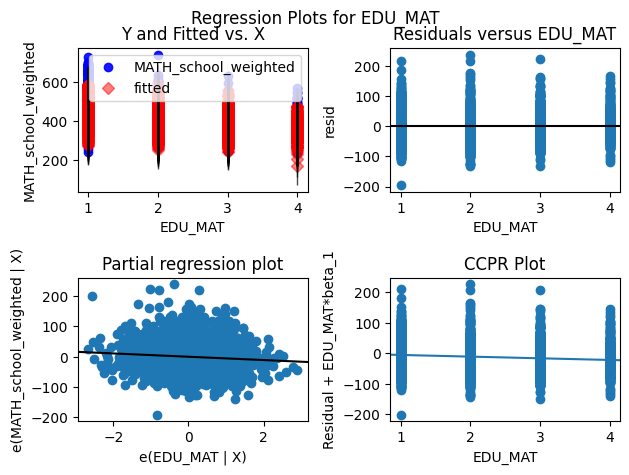

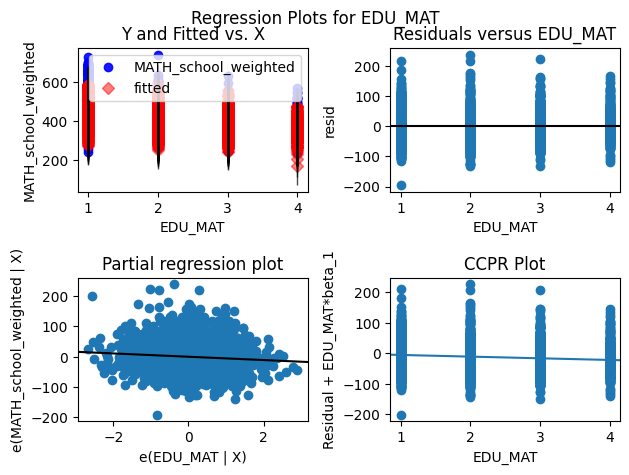

In [63]:
from statsmodels.stats.diagnostic import (
    linear_reset,
    het_breuschpagan,
    het_white
)
from statsmodels.stats.stattools import jarque_bera
import statsmodels.api as sm

# Residuals
resid = ols_res.resid

# 1. Ramsey RESET: functional-form/specification test
reset_test = linear_reset(
    ols_res,
    power=2,
    use_f=True
)

print("Ramsey RESET")
print("F-statistic:", reset_test.fvalue)
print("p-value:", reset_test.pvalue)


# 2. Breusch-Pagan: heteroskedasticity
bp = het_breuschpagan(resid, X_sm)

print("\nBreusch-Pagan")
print("LM statistic:", bp[0])
print("LM p-value:", bp[1])
print("F statistic:", bp[2])
print("F p-value:", bp[3])


# 3. White test: heteroskedasticity / some nonlinear misspecification
white = het_white(resid, X_sm)

print("\nWhite test")
print("LM statistic:", white[0])
print("LM p-value:", white[1])


# 4. Residual normality
jb = jarque_bera(resid)

print("\nJarque-Bera")
print("JB statistic:", jb[0])
print("p-value:", jb[1])


# 5. Residual-vs-fitted diagnostic
fitted = ols_res.fittedvalues

sm.graphics.plot_regress_exog(
    ols_res,
    ols_res.model.exog_names[1]
)

In [ ]:
import numpy as np
required_cols = (
    treatment_cols
    + student_confounders
    + school_confounders
    + ["PV1MATH", "CNTSCHID", "CNT", "year"]
)

tmp = df_final[required_cols].copy()
tmp = tmp.replace([np.inf, -np.inf], np.nan)
tmp = tmp.dropna()

print("Rows:", len(tmp))
print("Schools:", tmp["CNTSCHID"].nunique())

Rows: 93234
Schools: 1661


In [ ]:
tmp = df_final[
    treatment_cols +
    student_confounders +
    school_confounders +
    ["PV1MATH"]
]

print(tmp.isna().sum().sort_values(ascending=False))

REPEAT        7192
PV1MATH       5377
IMMIG         3943
SCHSIZE       3320
SC001Q01TA    1974
ESCS           706
SC025Q01NA       0
LANGN            0
ST001D01T        0
AGE              0
ST004D01T        0
EXT_FUND         0
EDU_MAT          0
SC037Q02TA       0
SC013Q01TA       0
PRNT_ENG         0
X_ACTIV          0
TCH_COMP         0
STU_COMP         0
STU_TCH          0
DIGI_CAP         0
EDU_INFRA        0
SC061Q01TA       0
dtype: int64


In [ ]:

print(df_final.loc[mask, "CNT"].value_counts())
print(df_final.loc[mask, "year"].value_counts())

print(X["CNT_VNM"].sum())
print(X["year_2022"].sum())

CNT
IDN    21913
THA    16400
PHL    13398
SGP    12476
BRN    12069
MYS     6704
VNM     5550
KHM     4724
Name: count, dtype: int64
year
2022    56136
2018    37098
Name: count, dtype: int64
5550.0
56136.0


In [ ]:
print(X_sm.shape)
print(np.linalg.matrix_rank(X_sm))

(93234, 31)
31


In [ ]:
country_schooltype_means = (
    school_df
    .groupby(["CNT", "SC013Q01TA"])["MATH_school_weighted"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
)

country_schooltype_means

,CNT,SC013Q01TA,count,mean,median,std
0,BRN,1.0,81,431.624409,415.156505,58.144959
1,BRN,2.0,28,488.196549,484.223882,34.659598
2,IDN,1.0,503,389.317805,378.320630,57.859336
3,IDN,2.0,304,371.077437,364.417779,47.186976
4,KHM,1.0,172,317.415532,314.226827,32.837233
5,KHM,2.0,11,401.409174,402.813223,47.487048
6,MYS,1.0,363,420.055640,410.661581,43.578863
7,MYS,2.0,27,467.455050,476.205351,64.839449
8,PHL,1.0,306,344.312200,340.387310,30.641152
9,PHL,2.0,69,398.044387,396.971038,47.533740


In [ ]:
ols_schooltype_means = (
    ols_df
    .groupby(["CNT", "SC013Q01TA"])["MATH_school_weighted"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
)

ols_schooltype_means

,CNT,SC013Q01TA,count,mean,median,std
0,BRN,1.0,81,431.624409,415.156505,58.144959
1,BRN,2.0,28,488.196549,484.223882,34.659598
2,IDN,1.0,503,389.317805,378.320630,57.859336
3,IDN,2.0,304,371.077437,364.417779,47.186976
4,KHM,1.0,172,317.415532,314.226827,32.837233
5,KHM,2.0,11,401.409174,402.813223,47.487048
6,MYS,1.0,363,420.055640,410.661581,43.578863
7,MYS,2.0,27,467.455050,476.205351,64.839449
8,PHL,1.0,306,344.312200,340.387310,30.641152
9,PHL,2.0,69,398.044387,396.971038,47.533740


In [ ]:
df_check = ols_df[
    ["MATH_school_weighted", "SC013Q01TA", "CNT"]
].dropna().copy()

df_check["private_school"] = (
    df_check["SC013Q01TA"] == 2
).astype(int)

country_fe = pd.get_dummies(
    df_check["CNT"],
    prefix="CNT",
    drop_first=True,
    dtype=float
)

X_check = pd.concat(
    [df_check[["private_school"]], country_fe],
    axis=1
)

X_check = sm.add_constant(X_check, has_constant="add")

result_country_only = sm.OLS(
    df_check["MATH_school_weighted"],
    X_check
).fit(cov_type="HC3")

print(result_country_only.summary().tables[1])

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            444.4425      5.592     79.483      0.000     433.483     455.402
private_school     6.6731      2.998      2.226      0.026       0.798      12.548
CNT_IDN          -64.5097      5.865    -10.999      0.000     -76.005     -53.014
CNT_KHM         -122.3793      6.280    -19.487      0.000    -134.688    -110.071
CNT_MYS          -21.5674      6.057     -3.561      0.000     -33.439      -9.696
CNT_PHL          -91.4714      5.894    -15.519      0.000    -103.024     -79.919
CNT_SGP          121.4036      6.311     19.238      0.000     109.035     133.772
CNT_THA          -27.3201      6.333     -4.314      0.000     -39.733     -14.907
CNT_VNM           11.5850      7.150      1.620      0.105      -2.428      25.598


In [ ]:
import pandas as pd
import statsmodels.api as sm

df_stage = ols_df.copy()

df_stage["private_school"] = (
    df_stage["SC013Q01TA"] == 2
).astype(int)

outcome = "MATH_school_weighted"

composition_controls = [
    "mean_ESCS",
    "mean_AGE",
    "mean_ST001D01T",
    "prop_ST004D01T_2.0",
    "prop_IMMIG_2.0",
    "prop_IMMIG_3.0",
    "prop_REPEAT_1.0",
]

school_controls = [
    "EDU_MAT",
    "EDU_INFRA",
    "DIGI_CAP",
    "STU_TCH",
    "STU_COMP",
    "TCH_COMP",
    "X_ACTIV",
    "PRNT_ENG",
    "SCHSIZE",
]

def fit_stage(data, predictors, country_fe=False, year_fe=False):
    required = [outcome, "private_school"] + predictors

    if country_fe:
        required.append("CNT")
    if year_fe:
        required.append("year")

    model_df = data[required].dropna().copy()

    parts = [model_df[["private_school"] + predictors].astype(float)]

    if country_fe:
        parts.append(
            pd.get_dummies(
                model_df["CNT"],
                prefix="CNT",
                drop_first=True,
                dtype=float,
            )
        )

    if year_fe:
        parts.append(
            pd.get_dummies(
                model_df["year"],
                prefix="year",
                drop_first=True,
                dtype=float,
            )
        )

    X_stage = pd.concat(parts, axis=1)
    X_stage = sm.add_constant(X_stage, has_constant="add")
    y_stage = model_df[outcome]

    result = sm.OLS(y_stage, X_stage).fit(cov_type="HC3")

    return {
        "coef": result.params["private_school"],
        "se": result.bse["private_school"],
        "p": result.pvalues["private_school"],
        "ci_low": result.conf_int().loc["private_school", 0],
        "ci_high": result.conf_int().loc["private_school", 1],
    }

staged_results = pd.DataFrame(
    {
 #       "M1_raw": fit_stage(df_stage, []),
        "SC013Q01TA_only": fit_stage(
            df_stage, [], country_fe=True, year_fe=True
        ),
        "SC013Q01TA_plus_student_controls": fit_stage(
            df_stage,
            composition_controls,
            country_fe=True,
            year_fe=True,
        ),
        "SC013Q01TA_plus_school_and_student_variables": fit_stage(
            df_stage,
            composition_controls + school_controls,
            country_fe=True,
            year_fe=True,
        ),
    }
).T

staged_results

,coef,se,p,ci_low,ci_high
SC013Q01TA_only,7.531437,2.970350,1.122747e-02,1.709657,13.353217
SC013Q01TA_plus_student_controls,-15.739435,2.186127,6.035004e-13,-20.024165,-11.454704
SC013Q01TA_plus_school_and_student_variables,-16.754618,2.315717,4.649287e-13,-21.293340,-12.215896


: 